In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
df = pd.read_csv('AEP_hourly.csv')

print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())

Shape: (121273, 2)

Column names: ['Datetime', 'AEP_MW']

First 5 rows:
              Datetime   AEP_MW
0  2004-12-31 01:00:00  13478.0
1  2004-12-31 02:00:00  12865.0
2  2004-12-31 03:00:00  12577.0
3  2004-12-31 04:00:00  12517.0
4  2004-12-31 05:00:00  12670.0


Chronologically sorted: True
Duplicate timestamps: 4
Data type of index: datetime64[us]

Date range:
Start: 2004-10-01 01:00:00
End: 2018-08-03 00:00:00

Total hours of data: 121273


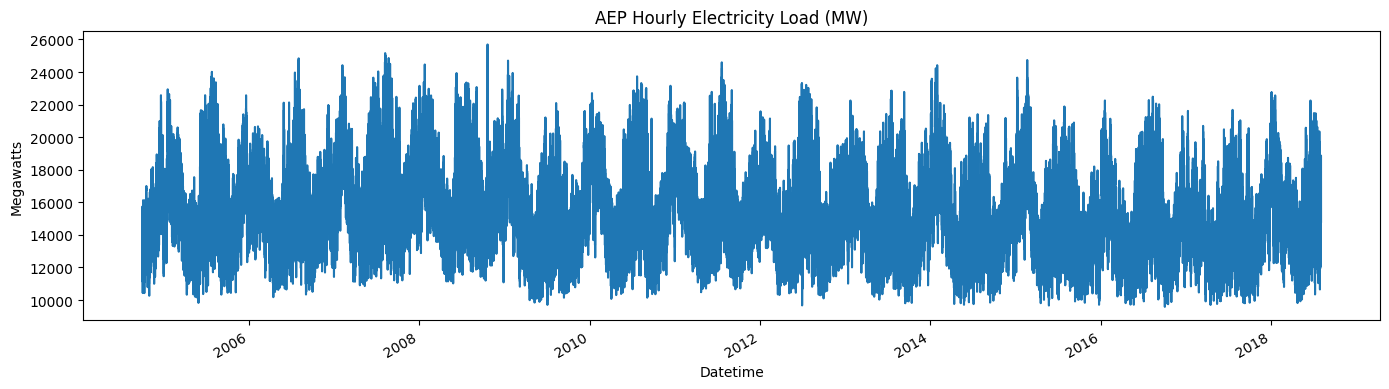

In [3]:
# Convert Datetime column to proper datetime format
df['Datetime'] = pd.to_datetime(df['Datetime'])

# Set Datetime as the index
df = df.set_index('Datetime').sort_index()
print("Chronologically sorted:", df.index.is_monotonic_increasing)
print("Duplicate timestamps:", df.index.duplicated().sum())

print("Data type of index:", df.index.dtype)
print("\nDate range:")
print("Start:", df.index.min())
print("End:", df.index.max())
print("\nTotal hours of data:", len(df))

# Plot the full dataset
df['AEP_MW'].plot(figsize=(14, 4), title='AEP Hourly Electricity Load (MW)')
plt.ylabel('Megawatts')
plt.tight_layout()
plt.show()

In [4]:
# Show all rows belonging to repeated timestamps
duplicate_rows = df[df.index.duplicated(keep=False)]
print("Rows at repeated timestamps:")
print(duplicate_rows)

# Check which hourly timestamps are absent
expected_hours = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

missing_hours = expected_hours.difference(df.index)

print("\nMissing hourly timestamps:", len(missing_hours))
print("First five missing timestamps:")
print(missing_hours[:5])

Rows at repeated timestamps:
                      AEP_MW
Datetime                    
2014-11-02 02:00:00  12994.0
2014-11-02 02:00:00  13190.0
2015-11-01 02:00:00  10785.0
2015-11-01 02:00:00  10542.0
2016-11-06 02:00:00  10964.0
2016-11-06 02:00:00  11008.0
2017-11-05 02:00:00  10596.0
2017-11-05 02:00:00  10446.0

Missing hourly timestamps: 27
First five missing timestamps:
DatetimeIndex(['2004-10-31 02:00:00', '2005-04-03 03:00:00',
               '2005-10-30 02:00:00', '2006-04-02 03:00:00',
               '2006-10-29 02:00:00'],
              dtype='datetime64[us]', freq=None)


In [5]:
# Preserve the data before this cleanup
df_before_cleanup = df.copy()

# Exclude both observations at each repeated timestamp
df = df.loc[~df.index.duplicated(keep=False)].copy()

# Create one row for every hourly timestamp
hourly_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

df = df.reindex(hourly_index)
df.index.name = "Datetime"

# Preserve the hourly series for rebuilding LSTM windows later
hourly_load = df["AEP_MW"].copy()

print("Duplicate timestamps:", df.index.duplicated().sum())
print("Total hourly rows:", len(df))
print("Missing load values:", df["AEP_MW"].isna().sum())

Duplicate timestamps: 0
Total hourly rows: 121296
Missing load values: 31


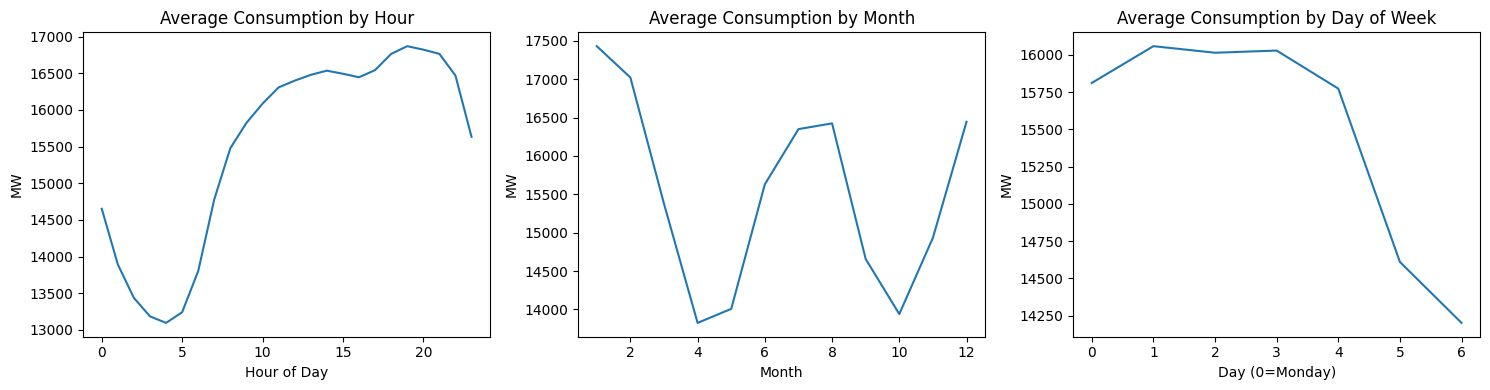

In [6]:
# Extract time features
df['hour'] = df.index.hour
df['month'] = df.index.month
df['dayofweek'] = df.index.dayofweek

# average consumption by hour
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df.groupby('hour')['AEP_MW'].mean().plot(ax=axes[0])
axes[0].set_title('Average Consumption by Hour')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('MW')

df.groupby('month')['AEP_MW'].mean().plot(ax=axes[1])
axes[1].set_title('Average Consumption by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('MW')

df.groupby('dayofweek')['AEP_MW'].mean().plot(ax=axes[2])
axes[2].set_title('Average Consumption by Day of Week')
axes[2].set_xlabel('Day (0=Monday)')
axes[2].set_ylabel('MW')

plt.tight_layout()
plt.show()

In [7]:

def create_features(df):
    df = df.copy()

    # Calendar features
    df["hour"] = df.index.hour
    df["dayofweek"] = df.index.dayofweek
    df["month"] = df.index.month
    df["quarter"] = df.index.quarter
    df["dayofyear"] = df.index.dayofyear

    # Past load values
    for lag in [1, 24, 48, 168]:
        df[f"lag_{lag}"] = df["AEP_MW"].shift(lag)

    # Past-only rolling averages
    df["rolling_mean_3"] = (
        df["AEP_MW"].shift(1).rolling(3, min_periods=3).mean()
    )
    df["rolling_mean_24"] = (
        df["AEP_MW"].shift(1).rolling(24, min_periods=24).mean()
    )

    return df


df = create_features(df)

features = [
    "hour", "dayofweek", "month", "quarter", "dayofyear",
    "lag_1", "lag_24", "lag_48", "lag_168",
    "rolling_mean_3", "rolling_mean_24"
]

# Require all previous 24 hours to be observed
valid_history = (
    df["AEP_MW"].notna()
    .rolling(window=24, min_periods=24)
    .sum()
    .shift(1)
    .eq(24)
)

# Keep df's hourly grid intact
model_df = df.loc[valid_history].dropna(
    subset=features + ["AEP_MW"]
).copy()

X = model_df[features]
y = model_df["AEP_MW"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(
    model_df[
        ["AEP_MW", "lag_1", "rolling_mean_3", "rolling_mean_24"]
    ].head()
)

Feature matrix shape: (120291, 11)
Target shape: (120291,)


,AEP_MW,lag_1,rolling_mean_3,rolling_mean_24
Datetime,,,,
2004-10-08 01:00:00,12468.0,13271.0,14345.666667,14450.333333
2004-10-08 02:00:00,12046.0,12468.0,13366.000000,14449.666667
2004-10-08 03:00:00,11749.0,12046.0,12595.000000,14449.333333
2004-10-08 04:00:00,11784.0,11749.0,12087.666667,14449.500000
2004-10-08 05:00:00,11919.0,11784.0,11859.666667,14450.625000


In [8]:
# Chronological 80/20 development-test split
test_start_position = int(len(model_df) * 0.80)

development = model_df.iloc[:test_start_position].copy()
test = model_df.iloc[test_start_position:].copy()

# Reserve the latest 20% of development data for validation
validation_start_position = int(len(development) * 0.80)

train = development.iloc[:validation_start_position].copy()
val = development.iloc[validation_start_position:].copy()

# Date boundaries also used by LSTM preparation and scaling
TRAIN_END = val.index.min()
VAL_END = test.index.min()

X_train = train[features]
y_train = train["AEP_MW"]

X_val = val[features]
y_val = val["AEP_MW"]

X_test = test[features]
y_test = test["AEP_MW"]

assert train.index.max() < val.index.min()
assert val.index.max() < test.index.min()

print("Development rows:", len(development))
print("Test rows:", len(test))

for name, part in [
    ("Training", train),
    ("Validation", val),
    ("Testing", test)
]:
    print(
        f"{name}: {len(part)} rows "
        f"({100 * len(part) / len(model_df):.2f}%)"
    )
    print(f"  {part.index.min()} to {part.index.max()}")

Development rows: 96232
Test rows: 24059
Training: 76985 rows (64.00%)
  2004-10-08 01:00:00 to 2013-08-12 05:00:00
Validation: 19247 rows (16.00%)
  2013-08-12 06:00:00 to 2015-10-28 19:00:00
Testing: 24059 rows (20.00%)
  2015-10-28 20:00:00 to 2018-08-03 00:00:00


## Preliminary one-hour-ahead experiments

These experiments use 11 engineered features for Linear Regression,
Random Forest and XGBoost. The initial LSTM uses only a 24-hour load
sequence, so the models do not receive identical information.

The main comparison with shared inputs appears in the next section.
Feature-importance plots in this section describe the preliminary models.

In [9]:
import xgboost as xgb
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.01,
    max_depth=5,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=42
)

# Fit on training data; monitor validation data only
model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

# Check validation performance
y_pred_val = model.predict(X_val)

val_rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
val_mae = mean_absolute_error(y_val, y_pred_val)

print("Best boosting round:", model.best_iteration + 1)
print(f"Validation RMSE: {val_rmse:.2f} MW")
print(f"Validation MAE: {val_mae:.2f} MW")

[0]	validation_0-rmse:2680.45174
[100]	validation_0-rmse:1078.22943
[200]	validation_0-rmse:522.49899
[300]	validation_0-rmse:347.09145
[400]	validation_0-rmse:291.88659
[500]	validation_0-rmse:265.65138
[600]	validation_0-rmse:251.73333
[700]	validation_0-rmse:239.40365
[800]	validation_0-rmse:230.08457
[900]	validation_0-rmse:222.73095
[999]	validation_0-rmse:217.15538
Best boosting round: 1000
Validation RMSE: 217.16 MW
Validation MAE: 169.44 MW


In [10]:
from sklearn.metrics import r2_score

def evaluate_predictions(actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()

    return {
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "MAPE (%)": np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100,
        "R2": r2_score(actual, predicted)
    }


# Preserve this trained model for the final comparison
xgb_model = model

validation_results = {}

# Simple baselines: repeat a previously observed load
for lag in [1, 24, 168]:
    validation_results[f"Naive {lag}h"] = evaluate_predictions(
        y_val,
        X_val[f"lag_{lag}"]
    )

validation_results["XGBoost"] = evaluate_predictions(
    y_val,
    xgb_model.predict(X_val)
)

print(
    pd.DataFrame(validation_results)
    .T
    .sort_values("RMSE (MW)")
    .round(3)
)  

            RMSE (MW)  MAE (MW)  MAPE (%)     R2
XGBoost       217.155   169.435     1.137  0.993
Naive 1h      541.240   420.091     2.844  0.956
Naive 24h    1353.337   996.897     6.525  0.727
Naive 168h   1873.482  1387.079     8.964  0.477


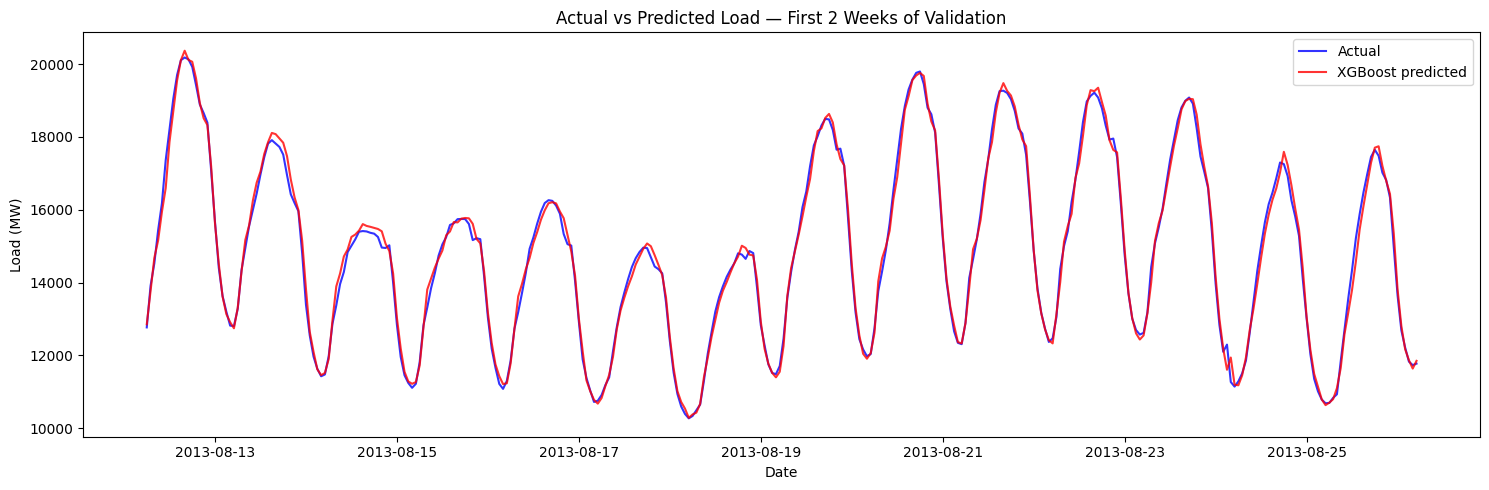

In [11]:
import matplotlib.pyplot as plt

# Keep predictions attached to their correct timestamps
val_plot = pd.DataFrame({
    "Actual": y_val,
    "XGBoost": xgb_model.predict(X_val)
})

# First 14 days of validation; preserve any missing-hour gaps
plot_hours = pd.date_range(
    start=y_val.index.min(),
    periods=14 * 24,
    freq="h"
)

val_plot = val_plot.reindex(plot_hours)

plt.figure(figsize=(15, 5))
plt.plot(val_plot.index, val_plot["Actual"],
         label="Actual", color="blue", alpha=0.8)
plt.plot(val_plot.index, val_plot["XGBoost"],
         label="XGBoost predicted", color="red", alpha=0.8)

plt.title("Actual vs Predicted Load — First 2 Weeks of Validation")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

                   RMSE (MW)  MAE (MW)  MAPE (%)     R2
XGBoost              217.155   169.435     1.137  0.993
Linear Regression    308.887   229.105     1.511  0.986
Naive 1h             541.240   420.091     2.844  0.956
Naive 24h           1353.337   996.897     6.525  0.727
Naive 168h          1873.482  1387.079     8.964  0.477


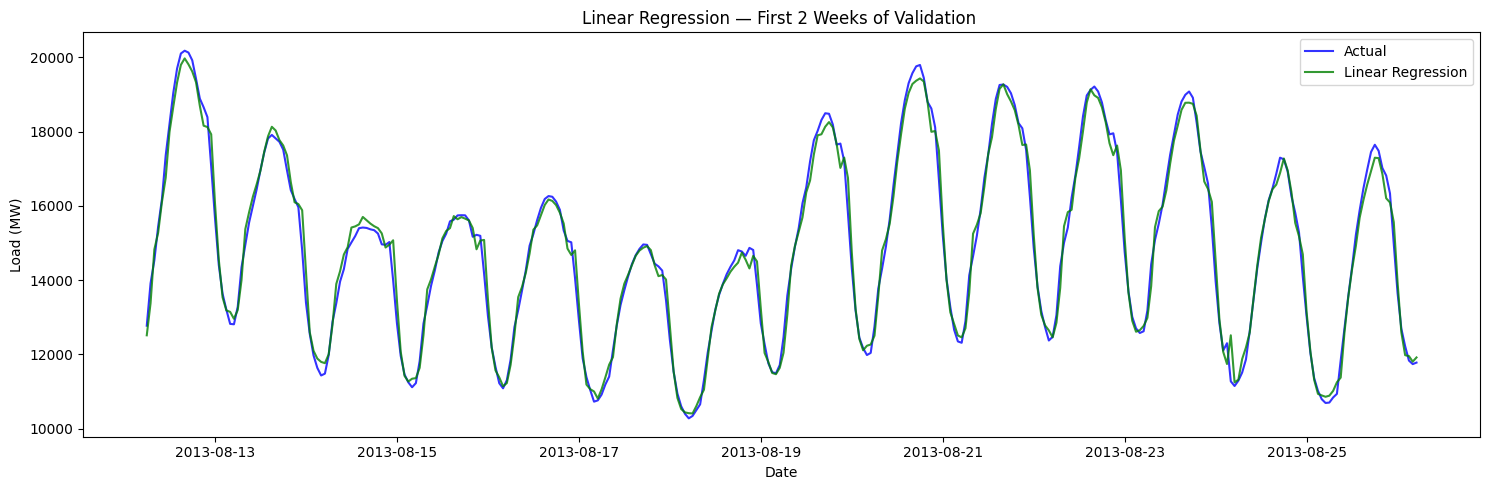

In [12]:
from sklearn.linear_model import LinearRegression

# Train using the same eleven features and training period
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr_val = lr_model.predict(X_val)

validation_results["Linear Regression"] = evaluate_predictions(
    y_val, y_pred_lr_val
)

# Show the updated comparison
print(
    pd.DataFrame(validation_results)
    .T
    .sort_values("RMSE (MW)")
    .round(3)
)

# Plot the same validation hours used for XGBoost
lr_plot = pd.DataFrame({
    "Actual": y_val,
    "Linear Regression": y_pred_lr_val
}).reindex(plot_hours)

plt.figure(figsize=(15, 5))
plt.plot(lr_plot.index, lr_plot["Actual"],
         label="Actual", color="blue", alpha=0.8)
plt.plot(lr_plot.index, lr_plot["Linear Regression"],
         label="Linear Regression", color="green", alpha=0.8)

plt.title("Linear Regression — First 2 Weeks of Validation ")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

                   RMSE (MW)  MAE (MW)  MAPE (%)     R2
XGBoost              217.155   169.435     1.137  0.993
Random Forest        218.363   162.961     1.079  0.993
Linear Regression    308.887   229.105     1.511  0.986
Naive 1h             541.240   420.091     2.844  0.956
Naive 24h           1353.337   996.897     6.525  0.727
Naive 168h          1873.482  1387.079     8.964  0.477


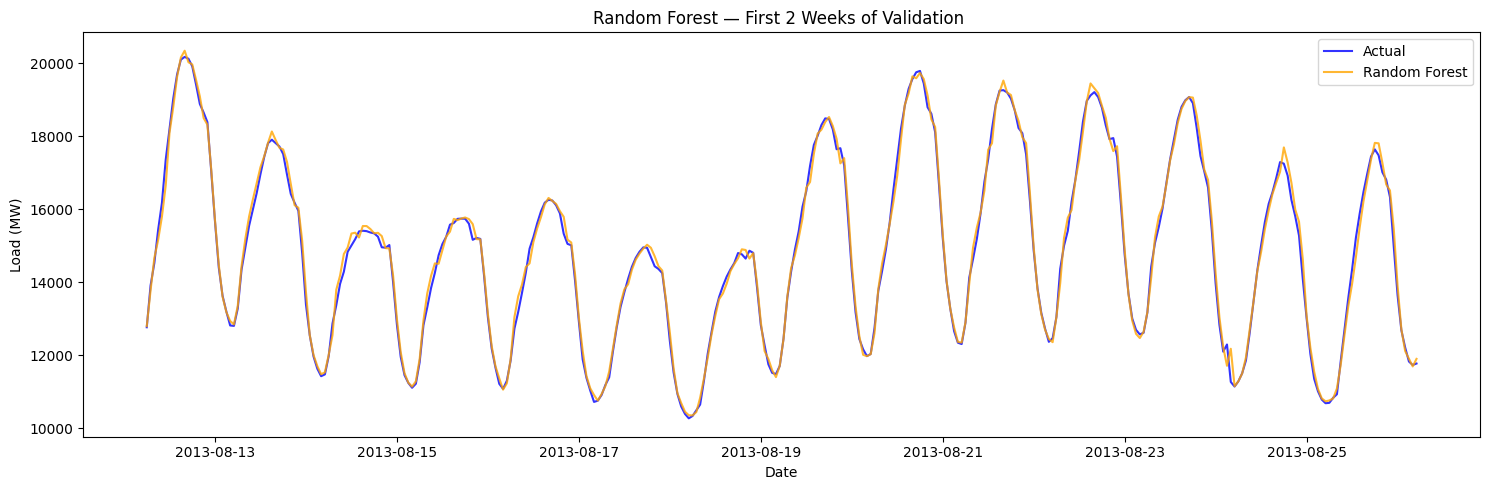

In [13]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf_val = rf_model.predict(X_val)

validation_results["Random Forest"] = evaluate_predictions(
    y_val, y_pred_rf_val
)

print(
    pd.DataFrame(validation_results)
    .T
    .sort_values("RMSE (MW)")
    .round(3)
)

# Plot the same validation hours
rf_plot = pd.DataFrame({
    "Actual": y_val,
    "Random Forest": y_pred_rf_val
}).reindex(plot_hours)

plt.figure(figsize=(15, 5))
plt.plot(rf_plot.index, rf_plot["Actual"],
         label="Actual", color="blue", alpha=0.8)
plt.plot(rf_plot.index, rf_plot["Random Forest"],
         label="Random Forest", color="orange", alpha=0.8)

plt.title("Random Forest — First 2 Weeks of Validation ")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Each fold trains on earlier observations and evaluates on later ones.
# Only X_train and y_train enter the search.
time_cv = TimeSeriesSplit(n_splits=3)

rf_grid = {
    "max_depth": [12, 18],
    "min_samples_leaf": [3, 5]
}

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_grid,
    scoring="neg_root_mean_squared_error",
    cv=time_cv,
    n_jobs=1,
    refit=True,
    verbose=2,
    error_score="raise"
)

rf_search.fit(X_train, y_train)

# Best settings from cross-validation, fitted on all training data
rf_tuned_model = rf_search.best_estimator_

print("Best parameters:", rf_search.best_params_)
print(
    "Mean cross-validation RMSE (MW):",
    round(-rf_search.best_score_, 3)
)

# Compare on the separate validation period
rf_tuning_comparison = pd.DataFrame({
    "Original Random Forest": evaluate_predictions(
    y_val, y_pred_rf_val
),
    "Tuned Random Forest": evaluate_predictions(
        y_val,
        rf_tuned_model.predict(X_val)
    )
}).T

display(rf_tuning_comparison)
rf_model = rf_tuned_model
validation_results["Random Forest"] = evaluate_predictions(
    y_val, rf_model.predict(X_val)
)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ...................max_depth=12, min_samples_leaf=3; total time=   2.3s
[CV] END ...................max_depth=12, min_samples_leaf=3; total time=   4.8s
[CV] END ...................max_depth=12, min_samples_leaf=3; total time=   7.2s
[CV] END ...................max_depth=12, min_samples_leaf=5; total time=   2.2s
[CV] END ...................max_depth=12, min_samples_leaf=5; total time=   4.7s
[CV] END ...................max_depth=12, min_samples_leaf=5; total time=   7.3s
[CV] END ...................max_depth=18, min_samples_leaf=3; total time=   2.7s
[CV] END ...................max_depth=18, min_samples_leaf=3; total time=   5.8s
[CV] END ...................max_depth=18, min_samples_leaf=3; total time=   9.2s
[CV] END ...................max_depth=18, min_samples_leaf=5; total time=   2.6s
[CV] END ...................max_depth=18, min_samples_leaf=5; total time=   6.0s
[CV] END ...................max_depth=18, min_sam

,RMSE (MW),MAE (MW),MAPE (%),R2
Original Random Forest,218.363072,162.960898,1.079364,0.992902
Tuned Random Forest,191.934073,141.776856,0.941667,0.994516


In [15]:
xgb_grid = {
    "learning_rate": [0.01, 0.05],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0]
}

# Fixed tree count during CV; no external validation set enters the search
xgb_search = GridSearchCV(
    estimator=xgb.XGBRegressor(
        n_estimators=1000,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1
    ),
    param_grid=xgb_grid,
    scoring="neg_root_mean_squared_error",
    cv=time_cv,
    n_jobs=1,
    refit=True,
    verbose=2,
    error_score="raise"
)

xgb_search.fit(X_train, y_train)
xgb_tuned_model = xgb_search.best_estimator_

print("Best parameters:", xgb_search.best_params_)
print(
    "Mean cross-validation RMSE (MW):",
    round(-xgb_search.best_score_, 3)
)

xgb_tuning_comparison = pd.DataFrame({
    "Original XGBoost": evaluate_predictions(
    y_val, y_pred_val
),
    "Tuned XGBoost": evaluate_predictions(
        y_val,
        xgb_tuned_model.predict(X_val)
    )
}).T

display(xgb_tuning_comparison)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END .....learning_rate=0.01, max_depth=3, subsample=0.8; total time=   0.9s
[CV] END .....learning_rate=0.01, max_depth=3, subsample=0.8; total time=   1.0s
[CV] END .....learning_rate=0.01, max_depth=3, subsample=0.8; total time=   1.2s
[CV] END .....learning_rate=0.01, max_depth=3, subsample=1.0; total time=   0.8s
[CV] END .....learning_rate=0.01, max_depth=3, subsample=1.0; total time=   1.0s
[CV] END .....learning_rate=0.01, max_depth=3, subsample=1.0; total time=   1.1s
[CV] END .....learning_rate=0.01, max_depth=5, subsample=0.8; total time=   1.4s
[CV] END .....learning_rate=0.01, max_depth=5, subsample=0.8; total time=   1.6s
[CV] END .....learning_rate=0.01, max_depth=5, subsample=0.8; total time=   1.8s
[CV] END .....learning_rate=0.01, max_depth=5, subsample=1.0; total time=   1.4s
[CV] END .....learning_rate=0.01, max_depth=5, subsample=1.0; total time=   1.6s
[CV] END .....learning_rate=0.01, max_depth=5, su

,RMSE (MW),MAE (MW),MAPE (%),R2
Original XGBoost,217.155376,169.435207,1.137302,0.992980
Tuned XGBoost,157.826569,121.500602,0.814791,0.996292


In [16]:
# Use the tuned models in subsequent evaluations and importance plots
rf_model = rf_tuned_model
xgb_model = xgb_tuned_model

validation_results["Random Forest"] = evaluate_predictions(
    y_val, rf_model.predict(X_val)
)
validation_results["XGBoost"] = evaluate_predictions(
    y_val, xgb_model.predict(X_val)
)

display(
    pd.DataFrame(validation_results).T
    .sort_values("RMSE (MW)")
)

,RMSE (MW),MAE (MW),MAPE (%),R2
XGBoost,157.826569,121.500602,0.814791,0.996292
Random Forest,191.934073,141.776856,0.941667,0.994516
Linear Regression,308.887228,229.104717,1.510838,0.985797
Naive 1h,541.240480,420.091287,2.844403,0.956391
Naive 24h,1353.337217,996.897127,6.524871,0.727350
Naive 168h,1873.482272,1387.079129,8.963921,0.477493


In [17]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

LOOKBACK = 24

# Fit the scaler using training observations only
scaler = MinMaxScaler()

training_load = hourly_load.loc[
    hourly_load.index < TRAIN_END
].dropna()

scaler.fit(training_load.to_numpy().reshape(-1, 1))

# Match target timestamps with the other models
seq_index = model_df.index
target_positions = hourly_load.index.get_indexer(seq_index)

assert (target_positions >= LOOKBACK).all()

# Collect the 24 hours BEFORE each target
history_positions = (
    target_positions[:, None]
    + np.arange(-LOOKBACK, 0)
)

raw_history = hourly_load.to_numpy()[history_positions]
raw_targets = model_df["AEP_MW"].to_numpy()

assert np.isfinite(raw_history).all()
assert np.isfinite(raw_targets).all()

# Transform using the training-fitted scaler
X_seq = scaler.transform(
    raw_history.reshape(-1, 1)
).reshape(-1, LOOKBACK, 1).astype("float32")

y_seq = scaler.transform(
    raw_targets.reshape(-1, 1)
).ravel().astype("float32")

# Split using each target's date
train_mask = seq_index < TRAIN_END
val_mask = (seq_index >= TRAIN_END) & (seq_index < VAL_END)
test_mask = seq_index >= VAL_END

X_train_seq, y_train_seq = X_seq[train_mask], y_seq[train_mask]
X_val_seq, y_val_seq = X_seq[val_mask], y_seq[val_mask]
X_test_seq, y_test_seq = X_seq[test_mask], y_seq[test_mask]

print("Training:", X_train_seq.shape, y_train_seq.shape)
print("Validation:", X_val_seq.shape, y_val_seq.shape)
print("Testing:", X_test_seq.shape, y_test_seq.shape)

Training: (76985, 24, 1) (76985,)
Validation: (19247, 24, 1) (19247,)
Testing: (24059, 24, 1) (24059,)


In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

tf.keras.utils.set_random_seed(42)

# Keep your original LSTM architecture
model_lstm = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

model_lstm.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model_lstm.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=20,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

best_epoch = np.argmin(history.history["val_loss"]) + 1
print("Best validation epoch:", best_epoch)

Epoch 1/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - loss: 0.0043 - mae: 0.0481 - val_loss: 8.1110e-04 - val_mae: 0.0226
Epoch 2/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 0.0011 - mae: 0.0250 - val_loss: 5.2033e-04 - val_mae: 0.0187
Epoch 3/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 7.1738e-04 - mae: 0.0202 - val_loss: 3.8231e-04 - val_mae: 0.0152
Epoch 4/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 6.7127e-04 - mae: 0.0195 - val_loss: 3.5011e-04 - val_mae: 0.0143
Epoch 5/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 6.2276e-04 - mae: 0.0189 - val_loss: 4.0810e-04 - val_mae: 0.0164
Epoch 6/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 6.0191e-04 - mae: 0.0184 - val_loss: 4.8641e-04 - val_mae: 0.0183
Epoch 7/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 5.6697e-04 - mae: 0.0179 - val_loss: 3.0852e-04 - val_mae: 0.0131
Epoch 8/20
2406/2406 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 5.5108e-04 - mae: 0.0175 - val_loss: 2.832

                   RMSE (MW)  MAE (MW)  MAPE (%)     R2
XGBoost              157.827   121.501     0.815  0.996
Random Forest        191.934   141.777     0.942  0.995
LSTM                 258.731   198.712     1.335  0.990
Linear Regression    308.887   229.105     1.511  0.986
Naive 1h             541.240   420.091     2.844  0.956
Naive 24h           1353.337   996.897     6.525  0.727
Naive 168h          1873.482  1387.079     8.964  0.477


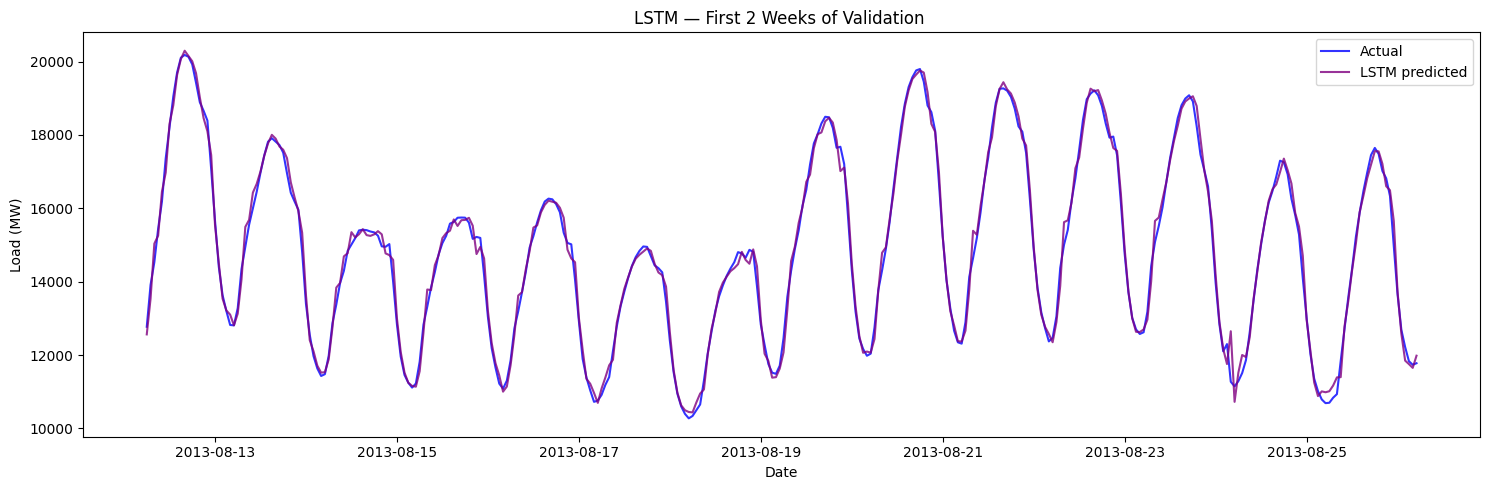

In [20]:
# Predict on validation data
pred_lstm_val_scaled = model_lstm.predict(
    X_val_seq,
    verbose=0
)

# Convert predictions back to MW
y_pred_lstm_val = scaler.inverse_transform(
    pred_lstm_val_scaled.reshape(-1, 1)
).ravel()

# Check that target timestamps match the other models
assert seq_index[val_mask].equals(y_val.index)

validation_results["LSTM"] = evaluate_predictions(
    y_val,
    y_pred_lstm_val
)

print(
    pd.DataFrame(validation_results)
    .T
    .sort_values("RMSE (MW)")
    .round(3)
)

# Plot the same two validation weeks
lstm_plot = pd.DataFrame({
    "Actual": y_val,
    "LSTM": y_pred_lstm_val
}).reindex(plot_hours)

plt.figure(figsize=(15, 5))
plt.plot(
    lstm_plot.index, lstm_plot["Actual"],
    label="Actual", color="blue", alpha=0.8
)
plt.plot(
    lstm_plot.index, lstm_plot["LSTM"],
    label="LSTM predicted", color="purple", alpha=0.8
)
plt.title("LSTM — First 2 Weeks of Validation ")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

### Effect of removing `lag_1`

This experiment removes only the previous-hour load feature. Other
features, including rolling averages of recent loads, remain available.
It measures the contribution of `lag_1`; it is not a 24-hour-ahead
forecast. The separate direct 24-hour-ahead experiment appears later.

In [21]:
from sklearn.base import clone

# Keep every other feature and model setting unchanged
features_without_lag1 = [
    feature for feature in features if feature != "lag_1"
]

xgb_without_lag1 = clone(xgb_model)

xgb_without_lag1.fit(
    X_train[features_without_lag1],
    y_train,
    eval_set=[(
        X_val[features_without_lag1],
        y_val
    )],
    verbose=False
)

pred_without_lag1 = xgb_without_lag1.predict(
    X_val[features_without_lag1]
)

lag_comparison = pd.DataFrame({
    "XGBoost with lag_1": validation_results["XGBoost"],
    "XGBoost without lag_1": evaluate_predictions(
        y_val, pred_without_lag1
    ),
    "Previous-hour baseline": validation_results["Naive 1h"]
}).T

print(lag_comparison.round(3))

                        RMSE (MW)  MAE (MW)  MAPE (%)     R2
XGBoost with lag_1        157.827   121.501     0.815  0.996
XGBoost without lag_1     284.698   216.691     1.429  0.988
Previous-hour baseline    541.240   420.091     2.844  0.956


In [22]:
# Choose the model using validation RMSE
model_names = [
    "Linear Regression", "Random Forest", "XGBoost", "LSTM"
]

selected_model = min(
    model_names,
    key=lambda name: validation_results[name]["RMSE (MW)"]
)

print("Selected using validation:", selected_model)

# Confirm identical test target timestamps
assert seq_index[test_mask].equals(y_test.index)
assert X_test.index.equals(y_test.index)

# Predict with the existing trained models
test_predictions = pd.DataFrame(index=y_test.index)
test_predictions["Actual"] = y_test
test_predictions["Linear Regression"] = lr_model.predict(X_test)
test_predictions["Random Forest"] = rf_model.predict(X_test)
test_predictions["XGBoost"] = xgb_model.predict(X_test)

lstm_test_scaled = model_lstm.predict(X_test_seq, verbose=0)
test_predictions["LSTM"] = scaler.inverse_transform(
    lstm_test_scaled.reshape(-1, 1)
).ravel()

# Include simple forecasting baselines
for lag in [1, 24, 168]:
    test_predictions[f"Naive {lag}h"] = X_test[f"lag_{lag}"]

assert np.isfinite(test_predictions.to_numpy()).all()

test_results = {
    name: evaluate_predictions(
        test_predictions["Actual"],
        test_predictions[name]
    )
    for name in test_predictions.columns
    if name != "Actual"
}

test_table = pd.DataFrame(test_results).T

print("Test targets:", len(test_predictions))
print(
    test_table.sort_values("RMSE (MW)").round(3)
)

Selected using validation: XGBoost
Test targets: 24059
                   RMSE (MW)  MAE (MW)  MAPE (%)     R2
XGBoost              173.296   131.091     0.904  0.995
Random Forest        210.201   152.391     1.052  0.993
LSTM                 247.610   188.893     1.304  0.990
Linear Regression    289.434   214.542     1.455  0.986
Naive 1h             526.707   408.696     2.813  0.954
Naive 24h           1224.198   923.944     6.258  0.749
Naive 168h          1911.669  1437.266     9.637  0.389


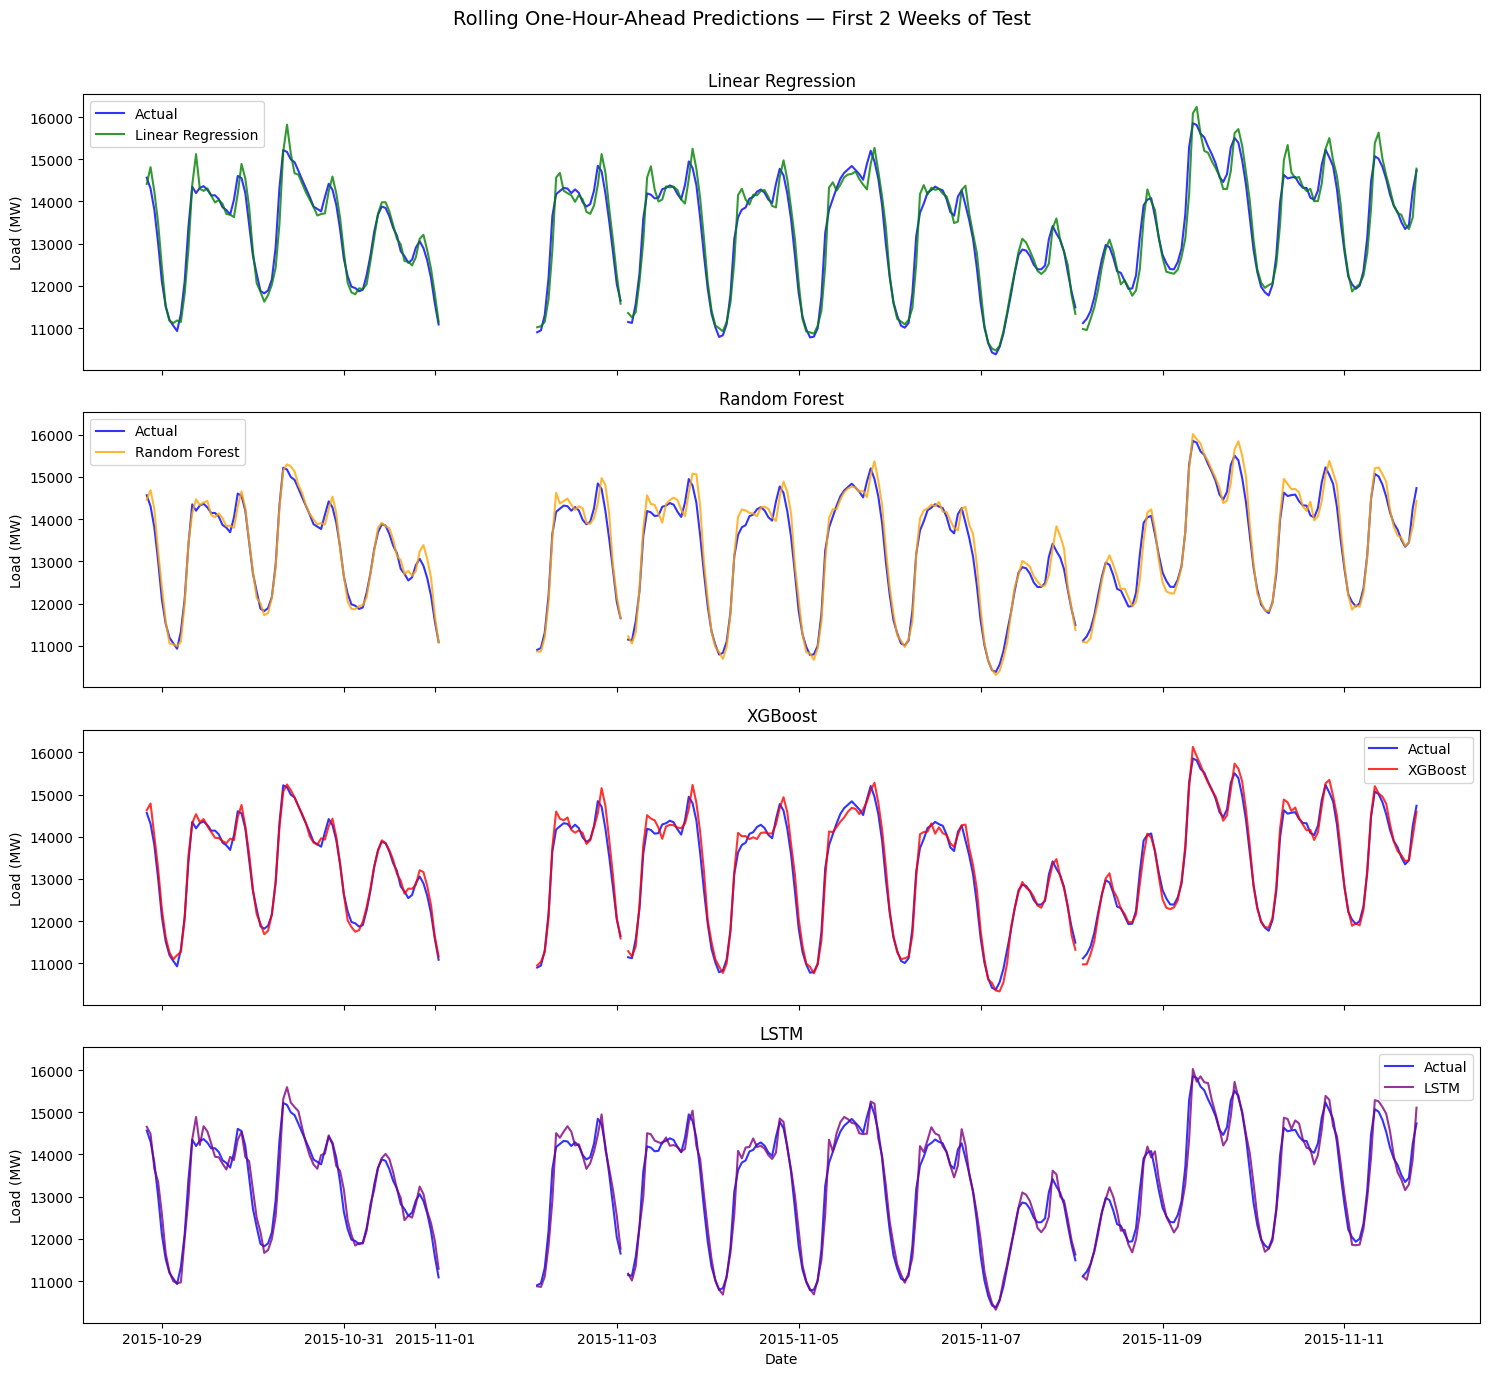

In [23]:
# Show identical test hours for every model
test_plot_hours = pd.date_range(
    start=test_predictions.index.min(),
    periods=14 * 24,
    freq="h"
)

test_plot = test_predictions.reindex(test_plot_hours)

fig, axes = plt.subplots(
    4, 1, figsize=(15, 14), sharex=True, sharey=True
)

colors = {
    "Linear Regression": "green",
    "Random Forest": "orange",
    "XGBoost": "red",
    "LSTM": "purple"
}

for ax, name in zip(axes, model_names):
    ax.plot(
        test_plot.index, test_plot["Actual"],
        label="Actual", color="blue", alpha=0.8
    )
    ax.plot(
        test_plot.index, test_plot[name],
        label=name, color=colors[name], alpha=0.8
    )
    ax.set_title(name)
    ax.set_ylabel("Load (MW)")
    ax.legend()

axes[-1].set_xlabel("Date")
fig.suptitle(
    "Rolling One-Hour-Ahead Predictions — First 2 Weeks of Test ",
    fontsize=14
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

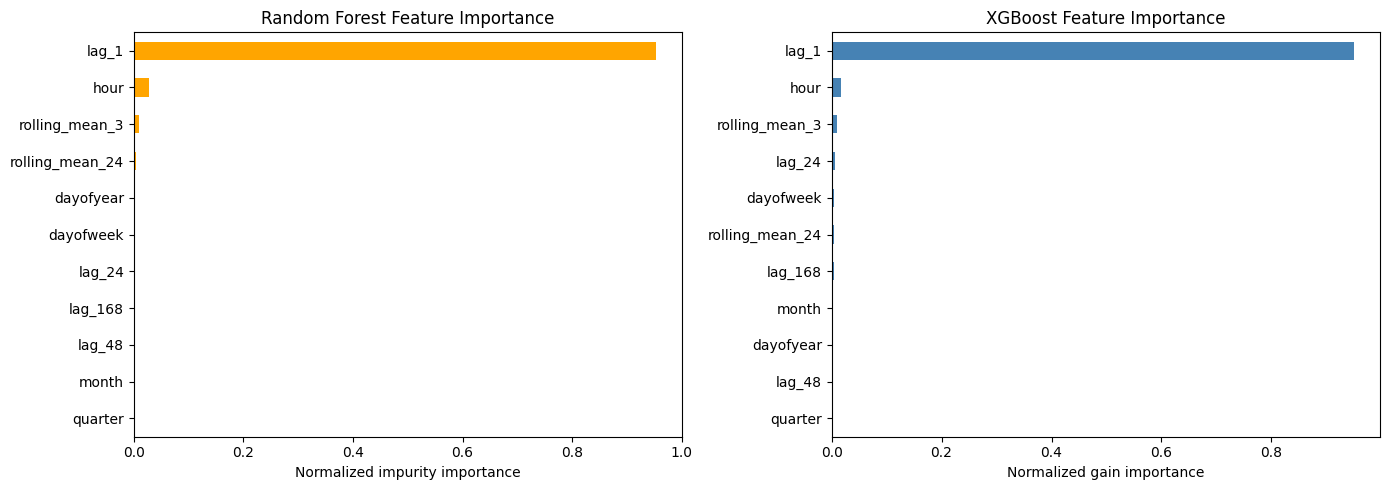

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_importances = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values()

rf_importances.plot(
    kind="barh", ax=axes[0], color="orange"
)
axes[0].set_title("Random Forest Feature Importance")
axes[0].set_xlabel("Normalized impurity importance")

xgb_importances = pd.Series(
    xgb_model.feature_importances_,
    index=features
).sort_values()

xgb_importances.plot(
    kind="barh", ax=axes[1], color="steelblue"
)
axes[1].set_title("XGBoost Feature Importance")
axes[1].set_xlabel("Normalized gain importance")

plt.tight_layout()
plt.show()

Selected using validation: XGBoost
                   Validation RMSE (MW)  Test RMSE (MW)  Test MAE (MW)  Test MAPE (%)  Test R2
Model                                                                                         
XGBoost                         157.827         173.296        131.091          0.904    0.995
Random Forest                   191.934         210.201        152.391          1.052    0.993
LSTM                            258.731         247.610        188.893          1.304    0.990
Linear Regression               308.887         289.434        214.542          1.455    0.986


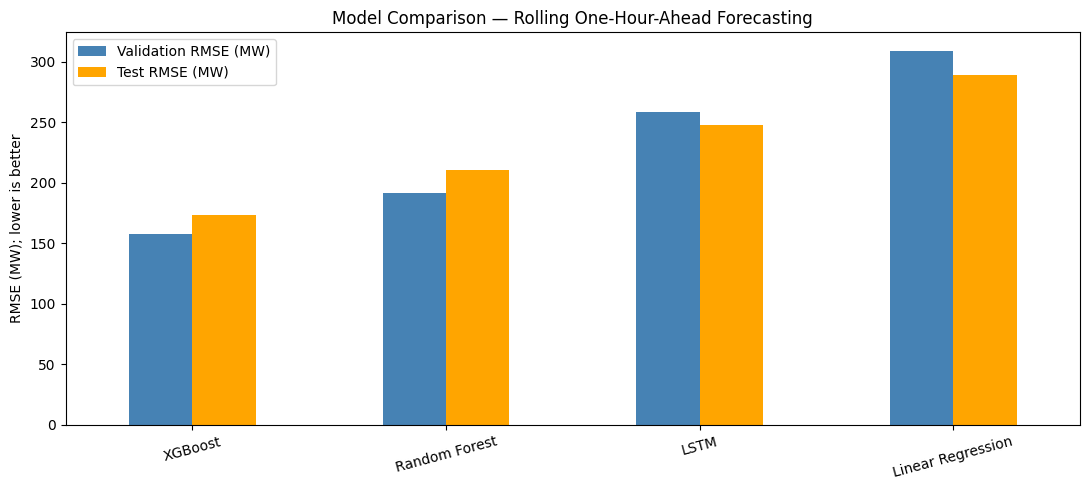

In [25]:
# Build the final summary from corrected results
validation_table = pd.DataFrame(validation_results).T

comparison = test_table.loc[model_names].copy()
comparison.index.name = "Model"

comparison.insert(
    0,
    "Validation RMSE (MW)",
    validation_table.loc[comparison.index, "RMSE (MW)"]
)

comparison = comparison.rename(columns={
    "RMSE (MW)": "Test RMSE (MW)",
    "MAE (MW)": "Test MAE (MW)",
    "MAPE (%)": "Test MAPE (%)",
    "R2": "Test R2"
}).sort_values("Validation RMSE (MW)")

print("Selected using validation:", selected_model)
print(comparison.round(3).to_string())

# Compare validation and retrospective test errors
ax = comparison[
    ["Validation RMSE (MW)", "Test RMSE (MW)"]
].plot(
    kind="bar",
    figsize=(11, 5),
    color=["steelblue", "orange"],
    rot=15
)

ax.set_title("Model Comparison — Rolling One-Hour-Ahead Forecasting")
ax.set_ylabel("RMSE (MW); lower is better")
ax.set_xlabel("")
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

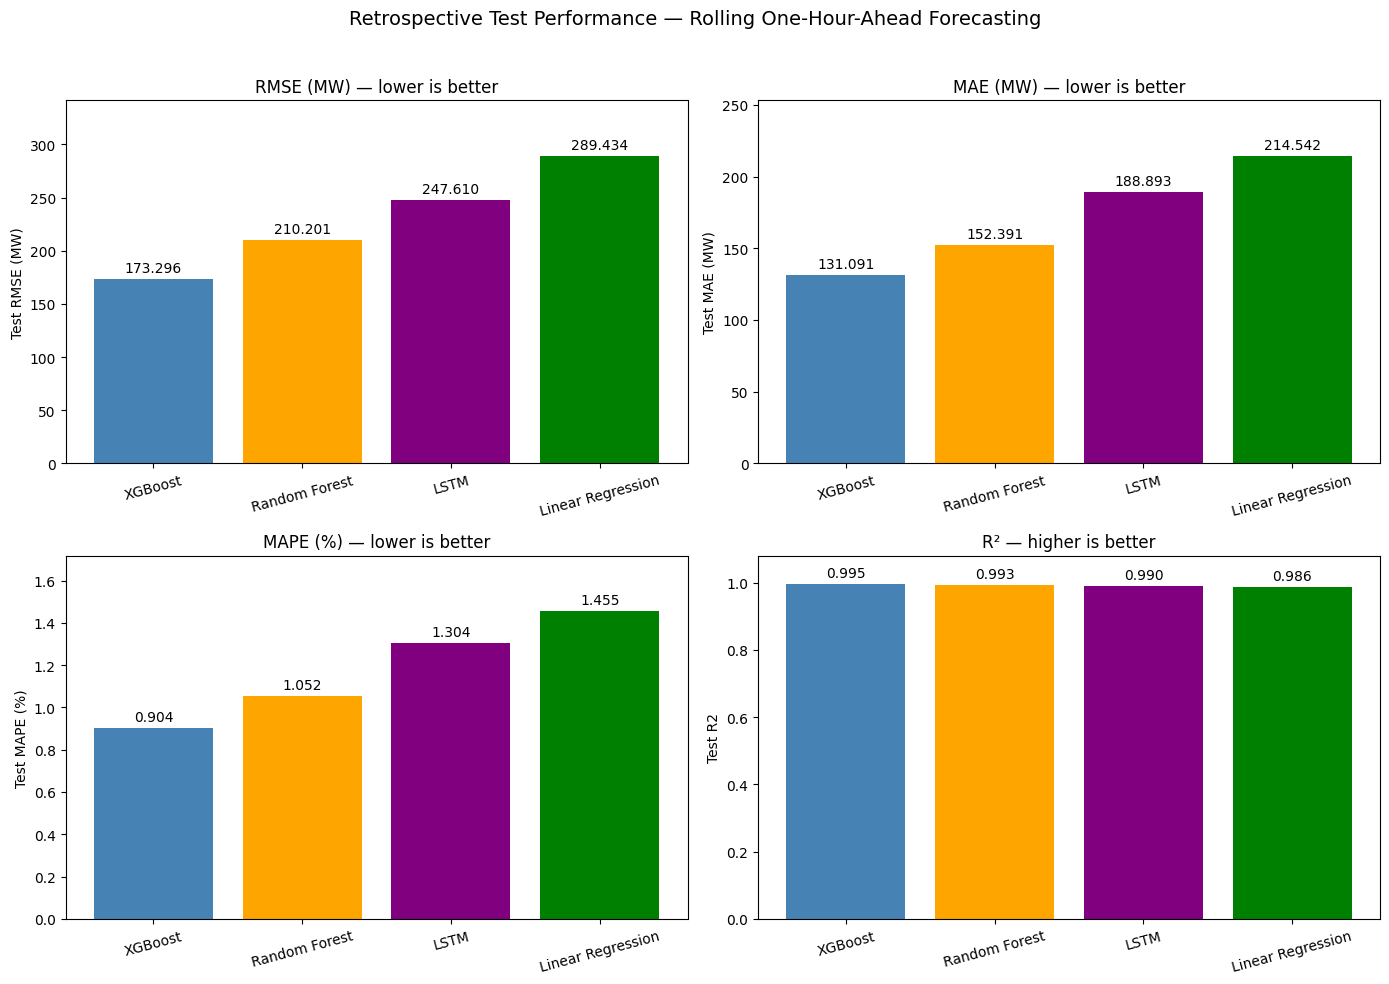

In [26]:
metrics_to_plot = [
    ("Test RMSE (MW)", "RMSE (MW) — lower is better"),
    ("Test MAE (MW)", "MAE (MW) — lower is better"),
    ("Test MAPE (%)", "MAPE (%) — lower is better"),
    ("Test R2", "R² — higher is better")
]

model_colors = {
    "Linear Regression": "green",
    "Random Forest": "orange",
    "XGBoost": "steelblue",
    "LSTM": "purple"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (column, title) in zip(axes.ravel(), metrics_to_plot):
    values = comparison[column]

    bars = ax.bar(
        comparison.index,
        values,
        color=[model_colors[name] for name in comparison.index]
    )

    ax.set_title(title)
    ax.set_ylabel(column)
    ax.tick_params(axis="x", rotation=15)
    ax.set_ylim(bottom=0)

    if column == "Test R2":
        ax.set_ylim(0, 1.08)
    else:
        ax.set_ylim(0, values.max() * 1.18)

    ax.bar_label(
        bars,
        labels=[f"{value:.3f}" for value in values],
        padding=3
    )

fig.suptitle(
    "Retrospective Test Performance — Rolling One-Hour-Ahead Forecasting",
    fontsize=14
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Main comparison: one-hour-ahead forecasting with shared inputs

All four models receive the same 24 historical hourly loads and 11
engineered features. Tabular models receive flattened history; the LSTM
receives a sequence plus a separate engineered-feature input.

Data is split chronologically into 64% training, 16% validation and 20%
test. Scalers are fitted on training data only. Model selection uses
validation RMSE.

LSTM architecture and learning rate are tuned using validation data;
Random Forest and XGBoost use chronological cross-validation.
Tuning methods and budgets differ. The main LSTM results use seed 42,
with additional seeds evaluated separately.

In [27]:
# Common inputs for a fair one-hour-ahead comparison
fair_h1_index = model_df.index.copy()

target_positions = hourly_load.index.get_indexer(fair_h1_index)
assert (target_positions >= 24).all()

# For target t, collect loads from t-24 through t-1
history_positions = (
    target_positions[:, None] + np.arange(-24, 0)
)

fair_h1_history = hourly_load.to_numpy()[
    history_positions
].reshape(-1, 24, 1)

# Identical engineered features for every model
fair_h1_context = model_df[features].copy()
fair_h1_y = model_df["AEP_MW"].copy()

# Flatten the same history for LR, RF and XGBoost
history_columns = [
    f"history_lag_{lag}" for lag in range(24, 0, -1)
]

fair_h1_X = pd.DataFrame(
    fair_h1_history[:, :, 0],
    index=fair_h1_index,
    columns=history_columns
).join(fair_h1_context.add_prefix("context_"))

# Keep the existing chronological boundaries
fair_h1_train_mask = fair_h1_index < TRAIN_END
fair_h1_val_mask = (
    (fair_h1_index >= TRAIN_END) &
    (fair_h1_index < VAL_END)
)
fair_h1_test_mask = fair_h1_index >= VAL_END

assert np.isfinite(fair_h1_history).all()
assert np.isfinite(fair_h1_X.to_numpy()).all()
assert fair_h1_X.index.equals(fair_h1_y.index)

# Confirm the sequence's latest load matches lag_1
np.testing.assert_array_equal(
    fair_h1_history[:, -1, 0],
    fair_h1_context["lag_1"].to_numpy()
)

print("LSTM history:", fair_h1_history.shape)
print("Common context:", fair_h1_context.shape)
print("Tabular inputs:", fair_h1_X.shape)
print(
    "Train / validation / test:",
    fair_h1_train_mask.sum(),
    fair_h1_val_mask.sum(),
    fair_h1_test_mask.sum()
)

LSTM history: (120291, 24, 1)
Common context: (120291, 11)
Tabular inputs: (120291, 35)
Train / validation / test: 76985 19247 24059


In [28]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Raw inputs for Linear Regression, Random Forest and XGBoost
fair_h1_X_train = fair_h1_X.loc[fair_h1_train_mask].copy()
fair_h1_X_val = fair_h1_X.loc[fair_h1_val_mask].copy()
fair_h1_X_test = fair_h1_X.loc[fair_h1_test_mask].copy()

fair_h1_y_train = fair_h1_y.loc[fair_h1_train_mask].copy()
fair_h1_y_val = fair_h1_y.loc[fair_h1_val_mask].copy()
fair_h1_y_test = fair_h1_y.loc[fair_h1_test_mask].copy()

# Separate scalers for the LSTM's history, context and target
fair_h1_history_scaler = MinMaxScaler()
fair_h1_context_scaler = StandardScaler()
fair_h1_target_scaler = MinMaxScaler()

# Fit ONLY on training inputs and targets
fair_h1_history_scaler.fit(
    fair_h1_history[fair_h1_train_mask].reshape(-1, 1)
)
fair_h1_context_scaler.fit(
    fair_h1_context.loc[fair_h1_train_mask]
)
fair_h1_target_scaler.fit(
    fair_h1_y_train.to_numpy().reshape(-1, 1)
)

def fair_h1_prepare_lstm(mask):
    history = fair_h1_history[mask]

    scaled_history = fair_h1_history_scaler.transform(
        history.reshape(-1, 1)
    ).reshape(history.shape).astype(np.float32)

    scaled_context = fair_h1_context_scaler.transform(
        fair_h1_context.loc[mask]
    ).astype(np.float32)

    scaled_target = fair_h1_target_scaler.transform(
        fair_h1_y.loc[mask].to_numpy().reshape(-1, 1)
    ).astype(np.float32)

    return scaled_history, scaled_context, scaled_target

(
    fair_h1_history_train,
    fair_h1_context_train,
    fair_h1_target_train
) = fair_h1_prepare_lstm(fair_h1_train_mask)

(
    fair_h1_history_val,
    fair_h1_context_val,
    fair_h1_target_val
) = fair_h1_prepare_lstm(fair_h1_val_mask)

(
    fair_h1_history_test,
    fair_h1_context_test,
    fair_h1_target_test
) = fair_h1_prepare_lstm(fair_h1_test_mask)

for name, history, context, target in [
    ("Train", fair_h1_history_train,
     fair_h1_context_train, fair_h1_target_train),
    ("Validation", fair_h1_history_val,
     fair_h1_context_val, fair_h1_target_val),
    ("Test", fair_h1_history_test,
     fair_h1_context_test, fair_h1_target_test),
]:
    assert len(history) == len(context) == len(target)
    assert all(
        np.isfinite(array).all()
        for array in (history, context, target)
    )
    print(name, history.shape, context.shape, target.shape)

Train (76985, 24, 1) (76985, 11) (76985, 1)
Validation (19247, 24, 1) (19247, 11) (19247, 1)
Test (24059, 24, 1) (24059, 11) (24059, 1)


In [29]:
import tensorflow as tf
from tensorflow.keras import Model, layers

def fair_h1_build_lstm(
    units=(64, 32),
    dropout=0.2,
    learning_rate=0.001,
    seed=42
):
    tf.keras.utils.set_random_seed(seed)

    # Input 1: chronological load history
    history_input = layers.Input(
        shape=(24, 1), name="load_history"
    )

    history_branch = layers.LSTM(
        units[0], return_sequences=True
    )(history_input)
    history_branch = layers.Dropout(dropout)(history_branch)
    history_branch = layers.LSTM(units[1])(history_branch)
    history_branch = layers.Dropout(dropout)(history_branch)

    # Input 2: calendar, lag and rolling-mean features
    context_input = layers.Input(
        shape=(fair_h1_context_train.shape[1],),
        name="engineered_features"
    )

    context_branch = layers.Dense(
        16, activation="relu"
    )(context_input)

    # Combine both sources of information
    combined = layers.Concatenate()(
        [history_branch, context_branch]
    )
    combined = layers.Dense(32, activation="relu")(combined)
    prediction = layers.Dense(1, name="predicted_load")(combined)

    model = Model(
        inputs=[history_input, context_input],
        outputs=prediction
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model

fair_h1_lstm = fair_h1_build_lstm()
fair_h1_lstm.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ load_history        │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 24, 64)    │     16,896 │ load_history[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 32)        │     12,416 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ engineered_features │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ lstm_3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        192 │ engineered_featu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48)        │          0 │ dropout_3[0][0],  │
│ (Concatenate)       │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      1,568 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predicted_load      │ (None, 1)         │         33 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,105 (121.50 KB)

 Trainable params: 31,105 (121.50 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
from sklearn.metrics import mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping

fair_h1_lstm_configs = [
    {"units": (64, 32), "learning_rate": 0.001},
    {"units": (64, 32), "learning_rate": 0.0003},
    {"units": (32, 16), "learning_rate": 0.001},
    {"units": (32, 16), "learning_rate": 0.0003},
]

fair_h1_lstm_search_rows = []
fair_h1_lstm_best_rmse = np.inf
fair_h1_lstm_best_weights = None

for trial, config in enumerate(fair_h1_lstm_configs, start=1):
    print(f"\nTrial {trial}/4: {config}", flush=True)

    tf.keras.backend.clear_session()

    candidate = fair_h1_build_lstm(
        units=config["units"],
        learning_rate=config["learning_rate"],
        dropout=0.2,
        seed=42
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = candidate.fit(
        [fair_h1_history_train, fair_h1_context_train],
        fair_h1_target_train,
        validation_data=(
            [fair_h1_history_val, fair_h1_context_val],
            fair_h1_target_val
        ),
        epochs=80,
        batch_size=128,
        shuffle=True,
        callbacks=[early_stopping],
        verbose=2
    )

    val_prediction_scaled = candidate.predict(
        [fair_h1_history_val, fair_h1_context_val],
        batch_size=256,
        verbose=0
    )

    val_prediction = fair_h1_target_scaler.inverse_transform(
        val_prediction_scaled
    ).ravel()

    val_rmse = np.sqrt(mean_squared_error(
        fair_h1_y_val.to_numpy(),
        val_prediction
    ))

    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    fair_h1_lstm_search_rows.append({
        "Units": str(config["units"]),
        "Learning rate": config["learning_rate"],
        "Best epoch": best_epoch,
        "Epochs run": len(history.history["loss"]),
        "Validation RMSE (MW)": val_rmse
    })

    print(f"Validation RMSE: {val_rmse:.2f} MW", flush=True)

    if val_rmse < fair_h1_lstm_best_rmse:
        fair_h1_lstm_best_rmse = val_rmse
        fair_h1_lstm_best_config = config.copy()
        fair_h1_lstm_best_weights = [
            weight.copy() for weight in candidate.get_weights()
        ]
        fair_h1_lstm_best_history = {
            key: values.copy()
            for key, values in history.history.items()
        }

    del candidate

# Restore the selected model without retraining it
tf.keras.backend.clear_session()

fair_h1_lstm = fair_h1_build_lstm(
    units=fair_h1_lstm_best_config["units"],
    learning_rate=fair_h1_lstm_best_config["learning_rate"],
    dropout=0.2,
    seed=42
)
fair_h1_lstm.set_weights(fair_h1_lstm_best_weights)

fair_h1_lstm_search_results = pd.DataFrame(
    fair_h1_lstm_search_rows
).sort_values("Validation RMSE (MW)")

display(fair_h1_lstm_search_results)

print("Selected configuration:", fair_h1_lstm_best_config)
print(f"Selected validation RMSE: {fair_h1_lstm_best_rmse:.2f} MW")


Trial 1/4: {'units': (64, 32), 'learning_rate': 0.001}
Epoch 1/80
602/602 - 13s - 22ms/step - loss: 0.0035 - mae: 0.0416 - val_loss: 0.0011 - val_mae: 0.0254
Epoch 2/80
602/602 - 11s - 19ms/step - loss: 8.3791e-04 - mae: 0.0222 - val_loss: 6.4251e-04 - val_mae: 0.0196
Epoch 3/80
602/602 - 11s - 19ms/step - loss: 5.4556e-04 - mae: 0.0177 - val_loss: 4.7311e-04 - val_mae: 0.0168
Epoch 4/80
602/602 - 11s - 19ms/step - loss: 4.4113e-04 - mae: 0.0158 - val_loss: 3.9092e-04 - val_mae: 0.0152
Epoch 5/80
602/602 - 11s - 19ms/step - loss: 3.8873e-04 - mae: 0.0147 - val_loss: 3.4153e-04 - val_mae: 0.0141
Epoch 6/80
602/602 - 11s - 19ms/step - loss: 3.5450e-04 - mae: 0.0141 - val_loss: 3.1443e-04 - val_mae: 0.0135
Epoch 7/80
602/602 - 11s - 19ms/step - loss: 3.2993e-04 - mae: 0.0136 - val_loss: 2.9614e-04 - val_mae: 0.0132
Epoch 8/80
602/602 - 11s - 19ms/step - loss: 3.0648e-04 - mae: 0.0131 - val_loss: 2.6558e-04 - val_mae: 0.0125
Epoch 9/80
602/602 - 11s - 19ms/step - loss: 2.7928e-04 - mae: 0

,Units,Learning rate,Best epoch,Epochs run,Validation RMSE (MW)
0,"(64, 32)",0.0010,39,44,155.372463
1,"(64, 32)",0.0003,79,80,161.710933
2,"(32, 16)",0.0010,41,46,168.121572
3,"(32, 16)",0.0003,79,80,172.402570


Selected configuration: {'units': (64, 32), 'learning_rate': 0.001}
Selected validation RMSE: 155.37 MW


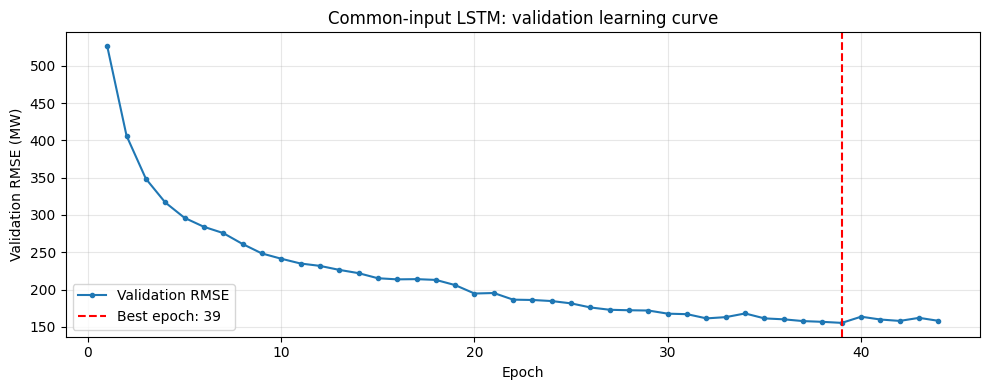

,Epoch,Validation RMSE (MW)
34,35,161.401039
35,36,160.142738
36,37,157.780432
37,38,156.780140
38,39,155.372449
39,40,163.678175
40,41,159.878556
41,42,158.026370
42,43,162.129516
43,44,158.142705


In [31]:
import matplotlib.pyplot as plt

fair_h1_val_losses = np.array(
    fair_h1_lstm_best_history["val_loss"]
)

# Convert scaled MSE into RMSE in MW
fair_h1_val_rmse_curve = (
    np.sqrt(fair_h1_val_losses)
    / fair_h1_target_scaler.scale_[0]
)

fair_h1_epochs = np.arange(
    1, len(fair_h1_val_rmse_curve) + 1
)
fair_h1_best_epoch = int(
    np.argmin(fair_h1_val_rmse_curve) + 1
)

plt.figure(figsize=(10, 4))
plt.plot(
    fair_h1_epochs,
    fair_h1_val_rmse_curve,
    marker=".",
    label="Validation RMSE"
)
plt.axvline(
    fair_h1_best_epoch,
    color="red",
    linestyle="--",
    label=f"Best epoch: {fair_h1_best_epoch}"
)
plt.xlabel("Epoch")
plt.ylabel("Validation RMSE (MW)")
plt.title("Common-input LSTM: validation learning curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Epoch": fair_h1_epochs,
    "Validation RMSE (MW)": fair_h1_val_rmse_curve
}).tail(10))

In [32]:
fair_h1_seed_rows = [{
    "Seed": 42,
    "Best epoch": int(np.argmin(
        fair_h1_lstm_best_history["val_loss"]
    ) + 1),
    "Epochs run": len(fair_h1_lstm_best_history["loss"]),
    "Validation RMSE (MW)": fair_h1_lstm_best_rmse
}]

# Preserve each run's weights for later evaluation
fair_h1_seed_weights = {
    42: [w.copy() for w in fair_h1_lstm_best_weights]
}

for seed in [7, 21]:
    print(f"\nTraining seed {seed}", flush=True)
    tf.keras.backend.clear_session()

    seed_model = fair_h1_build_lstm(
        units=fair_h1_lstm_best_config["units"],
        learning_rate=fair_h1_lstm_best_config["learning_rate"],
        dropout=0.2,
        seed=seed
    )

    seed_history = seed_model.fit(
        [fair_h1_history_train, fair_h1_context_train],
        fair_h1_target_train,
        validation_data=(
            [fair_h1_history_val, fair_h1_context_val],
            fair_h1_target_val
        ),
        epochs=80,
        batch_size=128,
        shuffle=True,
        callbacks=[EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )],
        verbose=2
    )

    prediction_scaled = seed_model.predict(
        [fair_h1_history_val, fair_h1_context_val],
        batch_size=256,
        verbose=0
    )

    prediction_mw = fair_h1_target_scaler.inverse_transform(
        prediction_scaled
    ).ravel()

    seed_rmse = np.sqrt(mean_squared_error(
        fair_h1_y_val.to_numpy(), prediction_mw
    ))

    fair_h1_seed_rows.append({
        "Seed": seed,
        "Best epoch": int(np.argmin(
            seed_history.history["val_loss"]
        ) + 1),
        "Epochs run": len(seed_history.history["loss"]),
        "Validation RMSE (MW)": seed_rmse
    })

    fair_h1_seed_weights[seed] = [
        w.copy() for w in seed_model.get_weights()
    ]

    del seed_model

# Keep the original seed-42 model for the main comparison
tf.keras.backend.clear_session()
fair_h1_lstm = fair_h1_build_lstm(
    units=fair_h1_lstm_best_config["units"],
    learning_rate=fair_h1_lstm_best_config["learning_rate"],
    dropout=0.2,
    seed=42
)
fair_h1_lstm.set_weights(fair_h1_seed_weights[42])

fair_h1_seed_results = pd.DataFrame(fair_h1_seed_rows)
display(fair_h1_seed_results)

scores = fair_h1_seed_results["Validation RMSE (MW)"]
print(f"Mean validation RMSE: {scores.mean():.2f} MW")
print(f"Sample standard deviation: {scores.std(ddof=1):.2f} MW")


Training seed 7
Epoch 1/80
602/602 - 14s - 23ms/step - loss: 0.0098 - mae: 0.0622 - val_loss: 0.0017 - val_mae: 0.0320
Epoch 2/80
602/602 - 11s - 18ms/step - loss: 0.0014 - mae: 0.0290 - val_loss: 8.8279e-04 - val_mae: 0.0233
Epoch 3/80
602/602 - 11s - 19ms/step - loss: 8.0434e-04 - mae: 0.0218 - val_loss: 6.3186e-04 - val_mae: 0.0198
Epoch 4/80
602/602 - 12s - 19ms/step - loss: 5.8499e-04 - mae: 0.0184 - val_loss: 5.0883e-04 - val_mae: 0.0177
Epoch 5/80
602/602 - 11s - 19ms/step - loss: 4.8881e-04 - mae: 0.0166 - val_loss: 4.1521e-04 - val_mae: 0.0155
Epoch 6/80
602/602 - 11s - 19ms/step - loss: 4.4410e-04 - mae: 0.0157 - val_loss: 3.7820e-04 - val_mae: 0.0147
Epoch 7/80
602/602 - 12s - 19ms/step - loss: 4.0890e-04 - mae: 0.0151 - val_loss: 3.4957e-04 - val_mae: 0.0141
Epoch 8/80
602/602 - 12s - 20ms/step - loss: 3.7808e-04 - mae: 0.0146 - val_loss: 3.1681e-04 - val_mae: 0.0134
Epoch 9/80
602/602 - 11s - 18ms/step - loss: 3.6127e-04 - mae: 0.0142 - val_loss: 3.1088e-04 - val_mae: 0.0

,Seed,Best epoch,Epochs run,Validation RMSE (MW)
0,42,39,44,155.372463
1,7,67,72,149.134519
2,21,77,80,140.919564


Mean validation RMSE: 148.48 MW
Sample standard deviation: 7.25 MW


In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# The scaler is fitted only on training data
fair_h1_lr = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

fair_h1_lr.fit(fair_h1_X_train, fair_h1_y_train)

fair_h1_lr_val_prediction = pd.Series(
    fair_h1_lr.predict(fair_h1_X_val),
    index=fair_h1_y_val.index,
    name="Linear Regression"
)

assert fair_h1_lr_val_prediction.index.equals(
    fair_h1_y_val.index
)
assert np.isfinite(fair_h1_lr_val_prediction).all()

fair_h1_lr_val_metrics = evaluate_predictions(
    fair_h1_y_val,
    fair_h1_lr_val_prediction
)

display(pd.DataFrame(
    [fair_h1_lr_val_metrics],
    index=["Linear Regression — common inputs"]
))

,RMSE (MW),MAE (MW),MAPE (%),R2
Linear Regression — common inputs,210.883258,157.892851,1.055786,0.99338


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

fair_h1_rf_search = GridSearchCV(
    estimator=RandomForestRegressor(
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [12, 18]
    },
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=3),
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

# Search and refit use training data only
fair_h1_rf_search.fit(
    fair_h1_X_train,
    fair_h1_y_train
)

fair_h1_rf = fair_h1_rf_search.best_estimator_

fair_h1_rf_val_prediction = pd.Series(
    fair_h1_rf.predict(fair_h1_X_val),
    index=fair_h1_y_val.index,
    name="Random Forest"
)

assert np.isfinite(fair_h1_rf_val_prediction).all()

fair_h1_rf_val_metrics = evaluate_predictions(
    fair_h1_y_val,
    fair_h1_rf_val_prediction
)

fair_h1_rf_cv_results = pd.DataFrame({
    "Parameters": fair_h1_rf_search.cv_results_["params"],
    "Mean CV RMSE (MW)": (
        -fair_h1_rf_search.cv_results_["mean_test_score"]
    )
}).sort_values("Mean CV RMSE (MW)")

display(fair_h1_rf_cv_results)
print("Selected parameters:", fair_h1_rf_search.best_params_)

display(pd.DataFrame(
    [fair_h1_rf_val_metrics],
    index=["Random Forest — common inputs"]
))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END .....................max_depth=12, n_estimators=100; total time=   4.9s
[CV] END .....................max_depth=12, n_estimators=100; total time=  10.8s
[CV] END .....................max_depth=12, n_estimators=100; total time=  17.7s
[CV] END .....................max_depth=12, n_estimators=200; total time=  10.4s
[CV] END .....................max_depth=12, n_estimators=200; total time=  24.7s
[CV] END .....................max_depth=12, n_estimators=200; total time=  34.8s
[CV] END .....................max_depth=18, n_estimators=100; total time=   5.8s
[CV] END .....................max_depth=18, n_estimators=100; total time=  13.2s
[CV] END .....................max_depth=18, n_estimators=100; total time=  20.9s
[CV] END .....................max_depth=18, n_estimators=200; total time=  11.9s
[CV] END .....................max_depth=18, n_estimators=200; total time=  27.6s
[CV] END .....................max_depth=18, n_est

,Parameters,Mean CV RMSE (MW)
3,"{'max_depth': 18, 'n_estimators': 200}",205.464597
2,"{'max_depth': 18, 'n_estimators': 100}",206.231735
1,"{'max_depth': 12, 'n_estimators': 200}",216.036554
0,"{'max_depth': 12, 'n_estimators': 100}",216.654064


Selected parameters: {'max_depth': 18, 'n_estimators': 200}


,RMSE (MW),MAE (MW),MAPE (%),R2
Random Forest — common inputs,183.772201,135.331249,0.898864,0.994972


In [35]:
from xgboost import XGBRegressor

fair_h1_xgb_search = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        n_estimators=1000,
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ),
    param_grid={
        "learning_rate": [0.03, 0.05],
        "max_depth": [3, 5],
        "subsample": [0.8, 1.0]
    },
    scoring="neg_root_mean_squared_error",
    cv=TimeSeriesSplit(n_splits=3),
    refit=False,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

# Select hyperparameters using training-period CV
fair_h1_xgb_search.fit(
    fair_h1_X_train,
    fair_h1_y_train
)

print("Selected parameters:", fair_h1_xgb_search.best_params_)

# Train with a larger cap; validation chooses when to stop
fair_h1_xgb = XGBRegressor(
    **fair_h1_xgb_search.best_params_,
    objective="reg:squarederror",
    n_estimators=3000,
    early_stopping_rounds=50,
    eval_metric="rmse",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

fair_h1_xgb.fit(
    fair_h1_X_train,
    fair_h1_y_train,
    eval_set=[(fair_h1_X_val, fair_h1_y_val)],
    verbose=100
)

fair_h1_xgb_val_prediction = pd.Series(
    fair_h1_xgb.predict(fair_h1_X_val),
    index=fair_h1_y_val.index,
    name="XGBoost"
)

assert np.isfinite(fair_h1_xgb_val_prediction).all()

fair_h1_xgb_val_metrics = evaluate_predictions(
    fair_h1_y_val,
    fair_h1_xgb_val_prediction
)

print("Best boosting round:", fair_h1_xgb.best_iteration + 1)

display(pd.DataFrame(
    [fair_h1_xgb_val_metrics],
    index=["XGBoost — common inputs"]
))

if fair_h1_xgb.best_iteration + 1 == 3000:
    print("Best round reached the cap; training may need review.")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END .....learning_rate=0.03, max_depth=3, subsample=0.8; total time=   1.3s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=0.8; total time=   1.6s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=0.8; total time=   1.8s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=1.0; total time=   1.4s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=1.0; total time=   1.5s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=1.0; total time=   1.8s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=0.8; total time=   2.7s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=0.8; total time=   3.4s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=0.8; total time=   3.8s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=1.0; total time=   2.4s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=1.0; total time=   2.6s
[CV] END .....learning_rate=0.03, max_depth=5, su

,RMSE (MW),MAE (MW),MAPE (%),R2
XGBoost — common inputs,140.018232,106.745569,0.713567,0.997081


Best round reached the cap; training may need review.


In [36]:
fair_h1_xgb.set_params(n_estimators=6000)

# Retrain from scratch with the same selected parameters
fair_h1_xgb.fit(
    fair_h1_X_train,
    fair_h1_y_train,
    eval_set=[(fair_h1_X_val, fair_h1_y_val)],
    verbose=500
)

fair_h1_xgb_val_prediction = pd.Series(
    fair_h1_xgb.predict(fair_h1_X_val),
    index=fair_h1_y_val.index,
    name="XGBoost"
)

assert np.isfinite(fair_h1_xgb_val_prediction).all()

fair_h1_xgb_val_metrics = evaluate_predictions(
    fair_h1_y_val,
    fair_h1_xgb_val_prediction
)

print("Selected parameters:", fair_h1_xgb_search.best_params_)
print("Best boosting round:", fair_h1_xgb.best_iteration + 1)

display(pd.DataFrame(
    [fair_h1_xgb_val_metrics],
    index=["XGBoost — common inputs"]
))

[0]	validation_0-rmse:2577.81942
[500]	validation_0-rmse:169.08121
[1000]	validation_0-rmse:152.86468
[1500]	validation_0-rmse:146.38262
[2000]	validation_0-rmse:143.37604
[2500]	validation_0-rmse:141.30678
[3000]	validation_0-rmse:140.01754
[3500]	validation_0-rmse:139.22904
[3976]	validation_0-rmse:138.75388
Selected parameters: {'learning_rate': 0.05, 'max_depth': 5, 'subsample': 0.8}
Best boosting round: 3927


,RMSE (MW),MAE (MW),MAPE (%),R2
XGBoost — common inputs,138.7452,105.831794,0.707421,0.997134


In [37]:
# LSTM validation predictions, converted back to MW
fair_h1_lstm_val_prediction = pd.Series(
    fair_h1_target_scaler.inverse_transform(
        fair_h1_lstm.predict(
            [fair_h1_history_val, fair_h1_context_val],
            batch_size=256,
            verbose=0
        )
    ).ravel(),
    index=fair_h1_y_val.index,
    name="LSTM"
)

fair_h1_val_predictions = pd.DataFrame({
    "Linear Regression": fair_h1_lr_val_prediction,
    "Random Forest": fair_h1_rf_val_prediction,
    "XGBoost": fair_h1_xgb_val_prediction,
    "LSTM": fair_h1_lstm_val_prediction
})

assert fair_h1_val_predictions.index.equals(fair_h1_y_val.index)
assert np.isfinite(fair_h1_val_predictions.to_numpy()).all()

fair_h1_validation_metrics = pd.DataFrame({
    name: evaluate_predictions(fair_h1_y_val, prediction)
    for name, prediction in fair_h1_val_predictions.items()
}).T

# Select among the four models using validation only
fair_h1_selected_model = (
    fair_h1_validation_metrics["RMSE (MW)"].idxmin()
)
print("Selected by validation RMSE:", fair_h1_selected_model)

# Test predictions from the already-trained models
fair_h1_test_predictions = pd.DataFrame({
    "Linear Regression": fair_h1_lr.predict(fair_h1_X_test),
    "Random Forest": fair_h1_rf.predict(fair_h1_X_test),
    "XGBoost": fair_h1_xgb.predict(fair_h1_X_test),
    "LSTM": fair_h1_target_scaler.inverse_transform(
        fair_h1_lstm.predict(
            [fair_h1_history_test, fair_h1_context_test],
            batch_size=256,
            verbose=0
        )
    ).ravel()
}, index=fair_h1_y_test.index)

# Previous-hour, previous-day and previous-week baselines
for lag in [1, 24, 168]:
    name = f"Naive lag {lag}h"

    fair_h1_val_predictions[name] = (
        fair_h1_context.loc[fair_h1_val_mask, f"lag_{lag}"]
    )
    fair_h1_test_predictions[name] = (
        fair_h1_context.loc[fair_h1_test_mask, f"lag_{lag}"]
    )

assert fair_h1_test_predictions.index.equals(fair_h1_y_test.index)
assert np.isfinite(fair_h1_test_predictions.to_numpy()).all()

# Evaluate every model and baseline on the same rows
fair_h1_validation_metrics = pd.DataFrame({
    name: evaluate_predictions(fair_h1_y_val, prediction)
    for name, prediction in fair_h1_val_predictions.items()
}).T

fair_h1_test_metrics = pd.DataFrame({
    name: evaluate_predictions(fair_h1_y_test, prediction)
    for name, prediction in fair_h1_test_predictions.items()
}).T

fair_h1_comparison = pd.concat({
    "Validation": fair_h1_validation_metrics,
    "Test": fair_h1_test_metrics
}, axis=1).sort_values(("Validation", "RMSE (MW)"))

print("Task: rolling one-hour-ahead prediction")
print("LSTM uses the retained seed-42 model.")
print("Common test samples:", len(fair_h1_y_test))
display(fair_h1_comparison.round(3))

Selected by validation RMSE: XGBoost
Task: rolling one-hour-ahead prediction
LSTM uses the retained seed-42 model.
Common test samples: 24059


Validation                                Test            \
                   RMSE (MW)  MAE (MW) MAPE (%)     R2 RMSE (MW)  MAE (MW)   
XGBoost              138.745   105.832    0.707  0.997   152.667   113.718   
LSTM                 155.372   118.825    0.794  0.996   171.077   126.904   
Random Forest        183.772   135.331    0.899  0.995   197.386   142.931   
Linear Regression    210.883   157.893    1.056  0.993   202.730   148.717   
Naive lag 1h         541.240   420.091    2.844  0.956   526.707   408.696   
Naive lag 24h       1353.337   996.897    6.525  0.727  1224.198   923.944   
Naive lag 168h      1873.482  1387.079    8.964  0.477  1911.669  1437.266   

                                   
                  MAPE (%)     R2  
XGBoost              0.784  0.996  
LSTM                 0.875  0.995  
Random Forest        0.985  0.993  
Linear Regression    1.020  0.993  
Naive lag 1h         2.813  0.954  
Naive lag 24h        6.258  0.749  
Naive lag 168h       9.637  0.389

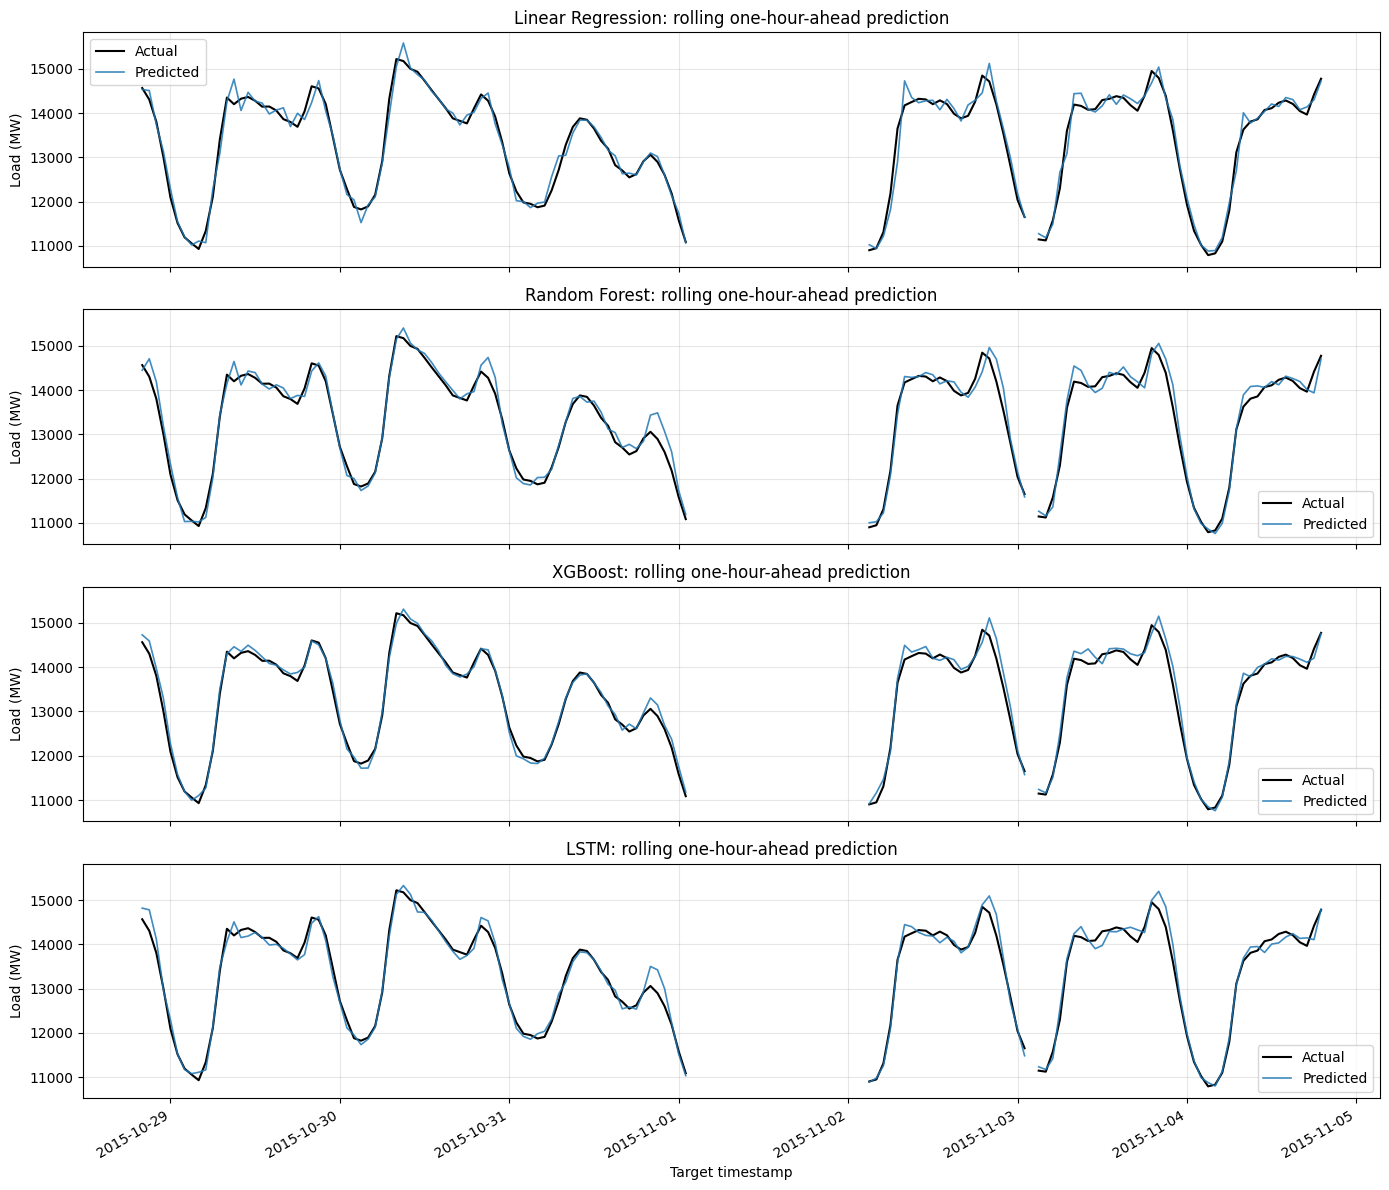

Hours without evaluation samples in this plot: 26


In [38]:
fair_h1_plot_start = fair_h1_y_test.index.min()
fair_h1_plot_end = fair_h1_plot_start + pd.Timedelta(days=7)

# Complete hourly axis so omitted timestamps appear as gaps
fair_h1_plot_index = pd.date_range(
    start=fair_h1_plot_start,
    end=fair_h1_plot_end,
    freq="h",
    inclusive="left"
)

fair_h1_plot_actual = fair_h1_y_test.reindex(
    fair_h1_plot_index
)
fair_h1_plot_predictions = fair_h1_test_predictions.reindex(
    fair_h1_plot_index
)

fair_h1_plot_models = [
    "Linear Regression",
    "Random Forest",
    "XGBoost",
    "LSTM"
]

fig, axes = plt.subplots(
    4, 1, figsize=(14, 12),
    sharex=True, sharey=True
)

for ax, name in zip(axes, fair_h1_plot_models):
    ax.plot(
        fair_h1_plot_actual,
        label="Actual", color="black", linewidth=1.5
    )
    ax.plot(
        fair_h1_plot_predictions[name],
        label="Predicted", linewidth=1.2, alpha=0.85
    )
    ax.set_title(f"{name}: rolling one-hour-ahead prediction")
    ax.set_ylabel("Load (MW)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Target timestamp")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(
    "Hours without evaluation samples in this plot:",
    fair_h1_plot_actual.isna().sum()
)

## Main comparison: direct 24-hour-ahead forecasting

Each prediction estimates one load value 24 hours after its forecast
origin. Forecast origins advance hourly; this experiment does not predict
an entire 24-hour profile from one origin.

All four models receive the same 24 historical loads ending at the
forecast origin, plus 11 engineered features. Target-hour calendar
features are known in advance; all load features use observations
available by the forecast origin.

The chronological boundaries follow the one-hour experiment, with
24-hour gaps before validation and test. Cross-validation also uses a
24-row gap, with timestamp checks confirming that training labels precede
validation forecast origins.

Scalers are fitted on training data only. Model selection uses validation
RMSE. Main LSTM results use seed 42; results from three seeds are reported
separately. Tuning methods and budgets differ across model families.

In [39]:
# Separate dataset for the 24-hour-ahead experiment
fair_h24_df = pd.DataFrame({
    "AEP_MW": hourly_load
})

# Calendar information for the TARGET hour is known in advance
fair_h24_df["hour"] = fair_h24_df.index.hour
fair_h24_df["dayofweek"] = fair_h24_df.index.dayofweek
fair_h24_df["month"] = fair_h24_df.index.month
fair_h24_df["quarter"] = fair_h24_df.index.quarter
fair_h24_df["dayofyear"] = fair_h24_df.index.dayofyear

# All load readings must be available by target time minus 24h
for lag in [24, 48, 72, 168]:
    fair_h24_df[f"lag_{lag}"] = hourly_load.shift(lag)

# Averages end at the forecast origin, NOT before the target hour
fair_h24_df["rolling_mean_3"] = (
    hourly_load.shift(24).rolling(3, min_periods=3).mean()
)
fair_h24_df["rolling_mean_24"] = (
    hourly_load.shift(24).rolling(24, min_periods=24).mean()
)

fair_h24_features = [
    "hour", "dayofweek", "month", "quarter", "dayofyear",
    "lag_24", "lag_48", "lag_72", "lag_168",
    "rolling_mean_3", "rolling_mean_24"
]

fair_h24_df = fair_h24_df.dropna(
    subset=fair_h24_features + ["AEP_MW"]
).copy()

fair_h24_origins = (
    fair_h24_df.index - pd.Timedelta(hours=24)
)

assert np.isfinite(
    fair_h24_df[fair_h24_features + ["AEP_MW"]].to_numpy()
).all()

print("Eligible samples:", len(fair_h24_df))
print("Engineered features:", len(fair_h24_features))
print("Example forecast origin:", fair_h24_origins[0])
print("Example target time:", fair_h24_df.index[0])

display(fair_h24_df.head(3))

Eligible samples: 120260
Engineered features: 11
Example forecast origin: 2004-10-07 01:00:00
Example target time: 2004-10-08 01:00:00


,AEP_MW,hour,dayofweek,month,quarter,dayofyear,lag_24,lag_48,lag_72,lag_168,rolling_mean_3,rolling_mean_24
Datetime,,,,,,,,,,,,
2004-10-08 01:00:00,12468.0,1,4,10,4,282,12484.0,12764.0,12532.0,12379.0,13335.000000,14400.958333
2004-10-08 02:00:00,12046.0,2,4,10,4,282,12054.0,12347.0,12126.0,11935.0,12595.666667,14388.750000
2004-10-08 03:00:00,11749.0,3,4,10,4,282,11745.0,12192.0,11926.0,11692.0,12094.333333,14370.125000


In [40]:
fair_h24_index = fair_h24_df.index.copy()

# Confirm that row shifts represent hours on the complete grid
assert hourly_load.index.equals(pd.date_range(
    hourly_load.index.min(),
    hourly_load.index.max(),
    freq="h"
))

fair_h24_target_positions = hourly_load.index.get_indexer(
    fair_h24_index
)
assert (fair_h24_target_positions >= 47).all()

# For target T, history runs from T-47h through T-24h.
# The latest reading is therefore at the forecast origin.
fair_h24_history_positions = (
    fair_h24_target_positions[:, None] + np.arange(-47, -23)
)

fair_h24_history = hourly_load.to_numpy()[
    fair_h24_history_positions
].reshape(-1, 24, 1)

fair_h24_context = fair_h24_df[fair_h24_features].copy()
fair_h24_y = fair_h24_df["AEP_MW"].copy()

# Tabular models receive the same history as separate columns
fair_h24_X = pd.DataFrame(
    fair_h24_history[:, :, 0],
    index=fair_h24_index,
    columns=[f"history_target_lag_{h}" for h in range(47, 23, -1)]
).join(fair_h24_context.add_prefix("context_"))

# Retain the existing date boundaries, with 24-hour gaps
fair_h24_gap = pd.Timedelta(hours=24)

fair_h24_train_mask = (
    fair_h24_index < TRAIN_END - fair_h24_gap
)
fair_h24_val_mask = (
    (fair_h24_index >= TRAIN_END) &
    (fair_h24_index < VAL_END - fair_h24_gap)
)
fair_h24_test_mask = fair_h24_index >= VAL_END

# Check shared inputs and their alignment
assert fair_h24_X.index.equals(fair_h24_y.index)
assert np.isfinite(fair_h24_X.to_numpy()).all()

np.testing.assert_array_equal(
    fair_h24_history[:, -1, 0],
    fair_h24_context["lag_24"].to_numpy()
)
np.testing.assert_allclose(
    fair_h24_history[:, :, 0].mean(axis=1),
    fair_h24_context["rolling_mean_24"].to_numpy()
)

# Earlier-period labels must precede the next forecast origins
assert fair_h24_index[fair_h24_train_mask].max() < (
    fair_h24_origins[fair_h24_val_mask].min()
)
assert fair_h24_index[fair_h24_val_mask].max() < (
    fair_h24_origins[fair_h24_test_mask].min()
)

print("LSTM history:", fair_h24_history.shape)
print("Common context:", fair_h24_context.shape)
print("Tabular inputs:", fair_h24_X.shape)
print(
    "Train / validation / test:",
    fair_h24_train_mask.sum(),
    fair_h24_val_mask.sum(),
    fair_h24_test_mask.sum()
)
print(
    "Samples excluded at split boundaries:",
    (~(
        fair_h24_train_mask |
        fair_h24_val_mask |
        fair_h24_test_mask
    )).sum()
)

LSTM history: (120260, 24, 1)
Common context: (120260, 11)
Tabular inputs: (120260, 35)
Train / validation / test: 76941 19218 24053
Samples excluded at split boundaries: 48


In [41]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Raw tabular inputs and targets
fair_h24_X_train = fair_h24_X.loc[fair_h24_train_mask].copy()
fair_h24_X_val = fair_h24_X.loc[fair_h24_val_mask].copy()
fair_h24_X_test = fair_h24_X.loc[fair_h24_test_mask].copy()

fair_h24_y_train = fair_h24_y.loc[fair_h24_train_mask].copy()
fair_h24_y_val = fair_h24_y.loc[fair_h24_val_mask].copy()
fair_h24_y_test = fair_h24_y.loc[fair_h24_test_mask].copy()

# Fresh scalers for this experiment
fair_h24_history_scaler = MinMaxScaler()
fair_h24_context_scaler = StandardScaler()
fair_h24_target_scaler = MinMaxScaler()

fair_h24_history_scaler.fit(
    fair_h24_history[fair_h24_train_mask].reshape(-1, 1)
)
fair_h24_context_scaler.fit(
    fair_h24_context.loc[fair_h24_train_mask]
)
fair_h24_target_scaler.fit(
    fair_h24_y_train.to_numpy().reshape(-1, 1)
)

def fair_h24_prepare_lstm(mask):
    history = fair_h24_history[mask]

    scaled_history = fair_h24_history_scaler.transform(
        history.reshape(-1, 1)
    ).reshape(history.shape).astype(np.float32)

    scaled_context = fair_h24_context_scaler.transform(
        fair_h24_context.loc[mask]
    ).astype(np.float32)

    scaled_target = fair_h24_target_scaler.transform(
        fair_h24_y.loc[mask].to_numpy().reshape(-1, 1)
    ).astype(np.float32)

    return scaled_history, scaled_context, scaled_target

(
    fair_h24_history_train,
    fair_h24_context_train,
    fair_h24_target_train
) = fair_h24_prepare_lstm(fair_h24_train_mask)

(
    fair_h24_history_val,
    fair_h24_context_val,
    fair_h24_target_val
) = fair_h24_prepare_lstm(fair_h24_val_mask)

(
    fair_h24_history_test,
    fair_h24_context_test,
    fair_h24_target_test
) = fair_h24_prepare_lstm(fair_h24_test_mask)

for name, history, context, target in [
    ("Train", fair_h24_history_train,
     fair_h24_context_train, fair_h24_target_train),
    ("Validation", fair_h24_history_val,
     fair_h24_context_val, fair_h24_target_val),
    ("Test", fair_h24_history_test,
     fair_h24_context_test, fair_h24_target_test),
]:
    assert len(history) == len(context) == len(target)
    assert all(
        np.isfinite(array).all()
        for array in (history, context, target)
    )
    print(name, history.shape, context.shape, target.shape)

Train (76941, 24, 1) (76941, 11) (76941, 1)
Validation (19218, 24, 1) (19218, 11) (19218, 1)
Test (24053, 24, 1) (24053, 11) (24053, 1)


In [42]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

fair_h24_lr = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

fair_h24_lr.fit(fair_h24_X_train, fair_h24_y_train)

fair_h24_lr_val_prediction = pd.Series(
    fair_h24_lr.predict(fair_h24_X_val),
    index=fair_h24_y_val.index,
    name="Linear Regression"
)

assert np.isfinite(fair_h24_lr_val_prediction).all()

fair_h24_lr_val_metrics = evaluate_predictions(
    fair_h24_y_val,
    fair_h24_lr_val_prediction
)

fair_h24_initial_val_predictions = pd.DataFrame({
    "Linear Regression": fair_h24_lr_val_prediction,
    "Naive lag 24h": fair_h24_context.loc[
        fair_h24_val_mask, "lag_24"
    ],
    "Naive lag 168h": fair_h24_context.loc[
        fair_h24_val_mask, "lag_168"
    ]
})

assert fair_h24_initial_val_predictions.index.equals(
    fair_h24_y_val.index
)
assert np.isfinite(
    fair_h24_initial_val_predictions.to_numpy()
).all()

fair_h24_initial_val_metrics = pd.DataFrame({
    name: evaluate_predictions(fair_h24_y_val, prediction)
    for name, prediction in fair_h24_initial_val_predictions.items()
}).T

print("Task: direct 24-hour-ahead prediction")
display(fair_h24_initial_val_metrics.round(3))

Task: direct 24-hour-ahead prediction


,RMSE (MW),MAE (MW),MAPE (%),R2
Linear Regression,1050.334,800.536,5.258,0.836
Naive lag 24h,1348.718,993.732,6.511,0.729
Naive lag 168h,1876.261,1391.270,8.997,0.476


In [43]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

fair_h24_cv = TimeSeriesSplit(n_splits=3, gap=24)

# Check that training labels are available before validation forecasts.
for train_positions, val_positions in fair_h24_cv.split(fair_h24_X_train):
    last_train_target = fair_h24_X_train.index[train_positions].max()
    first_val_origin = (
        fair_h24_X_train.index[val_positions].min()
        - pd.Timedelta(hours=24)
    )
    assert last_train_target < first_val_origin

fair_h24_rf_search = GridSearchCV(
    estimator=RandomForestRegressor(
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [12, 18]
    },
    scoring="neg_root_mean_squared_error",
    cv=fair_h24_cv,
    n_jobs=1,
    refit=True,
    verbose=2
)

fair_h24_rf_search.fit(fair_h24_X_train, fair_h24_y_train)
fair_h24_rf = fair_h24_rf_search.best_estimator_

fair_h24_rf_val_prediction = pd.Series(
    fair_h24_rf.predict(fair_h24_X_val),
    index=fair_h24_y_val.index,
    name="Random Forest"
)
assert np.isfinite(fair_h24_rf_val_prediction).all()

fair_h24_rf_val_metrics = evaluate_predictions(
    fair_h24_y_val,
    fair_h24_rf_val_prediction
)

print("Best parameters:", fair_h24_rf_search.best_params_)
print(
    "Mean CV RMSE:",
    round(-fair_h24_rf_search.best_score_, 3),
    "MW"
)

display(pd.DataFrame({
    "Linear Regression": fair_h24_lr_val_metrics,
    "Random Forest": fair_h24_rf_val_metrics
}).T.round(3))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END .....................max_depth=12, n_estimators=100; total time=   5.9s
[CV] END .....................max_depth=12, n_estimators=100; total time=  13.2s
[CV] END .....................max_depth=12, n_estimators=100; total time=  19.3s
[CV] END .....................max_depth=12, n_estimators=200; total time=  11.5s
[CV] END .....................max_depth=12, n_estimators=200; total time=  24.5s
[CV] END .....................max_depth=12, n_estimators=200; total time=  40.1s
[CV] END .....................max_depth=18, n_estimators=100; total time=   7.1s
[CV] END .....................max_depth=18, n_estimators=100; total time=  15.1s
[CV] END .....................max_depth=18, n_estimators=100; total time=  23.7s
[CV] END .....................max_depth=18, n_estimators=200; total time=  14.3s
[CV] END .....................max_depth=18, n_estimators=200; total time=  33.2s
[CV] END .....................max_depth=18, n_est

,RMSE (MW),MAE (MW),MAPE (%),R2
Linear Regression,1050.334,800.536,5.258,0.836
Random Forest,984.755,730.315,4.764,0.856


In [44]:
from xgboost import XGBRegressor

fair_h24_xgb_search = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        n_estimators=1000,
        random_state=42,
        n_jobs=-1
    ),
    param_grid={
        "learning_rate": [0.03, 0.05],
        "max_depth": [3, 5],
        "subsample": [0.8, 1.0]
    },
    scoring="neg_root_mean_squared_error",
    cv=fair_h24_cv,
    n_jobs=1,
    refit=False,
    verbose=2
)

fair_h24_xgb_search.fit(
    fair_h24_X_train,
    fair_h24_y_train
)

print("Best parameters:", fair_h24_xgb_search.best_params_)
print(
    "Mean CV RMSE:",
    round(-fair_h24_xgb_search.best_score_, 3),
    "MW"
)

fair_h24_xgb_search_results = pd.DataFrame(
    fair_h24_xgb_search.cv_results_
)
fair_h24_xgb_search_results["CV RMSE (MW)"] = (
    -fair_h24_xgb_search_results["mean_test_score"]
)

display(
    fair_h24_xgb_search_results[
        [
            "param_learning_rate",
            "param_max_depth",
            "param_subsample",
            "CV RMSE (MW)"
        ]
    ].sort_values("CV RMSE (MW)").round(3)
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END .....learning_rate=0.03, max_depth=3, subsample=0.8; total time=   1.3s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=0.8; total time=   1.5s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=0.8; total time=   1.8s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=1.0; total time=   1.2s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=1.0; total time=   1.4s
[CV] END .....learning_rate=0.03, max_depth=3, subsample=1.0; total time=   1.7s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=0.8; total time=   2.1s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=0.8; total time=   2.5s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=0.8; total time=   2.9s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=1.0; total time=   2.1s
[CV] END .....learning_rate=0.03, max_depth=5, subsample=1.0; total time=   2.4s
[CV] END .....learning_rate=0.03, max_depth=5, su

,param_learning_rate,param_max_depth,param_subsample,CV RMSE (MW)
0,0.03,3,0.8,943.181
1,0.03,3,1.0,945.509
5,0.05,3,1.0,946.230
4,0.05,3,0.8,948.975
2,0.03,5,0.8,949.332
3,0.03,5,1.0,949.859
6,0.05,5,0.8,959.023
7,0.05,5,1.0,961.171


In [45]:
fair_h24_xgb = XGBRegressor(
    **fair_h24_xgb_search.best_params_,
    objective="reg:squarederror",
    tree_method="hist",
    n_estimators=6000,
    early_stopping_rounds=50,
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

fair_h24_xgb.fit(
    fair_h24_X_train,
    fair_h24_y_train,
    eval_set=[(fair_h24_X_val, fair_h24_y_val)],
    verbose=200
)

fair_h24_xgb_val_prediction = pd.Series(
    fair_h24_xgb.predict(fair_h24_X_val),
    index=fair_h24_y_val.index,
    name="XGBoost"
)
assert np.isfinite(fair_h24_xgb_val_prediction).all()

fair_h24_xgb_val_metrics = evaluate_predictions(
    fair_h24_y_val,
    fair_h24_xgb_val_prediction
)

print("Best boosting round:", fair_h24_xgb.best_iteration + 1)
print(
    "Rounds actually run:",
    len(fair_h24_xgb.evals_result()["validation_0"]["rmse"])
)

display(pd.DataFrame({
    "Linear Regression": fair_h24_lr_val_metrics,
    "Random Forest": fair_h24_rf_val_metrics,
    "XGBoost": fair_h24_xgb_val_metrics
}).T.round(3))

[0]	validation_0-rmse:2645.47360
[200]	validation_0-rmse:1008.45748
[400]	validation_0-rmse:981.71756
[600]	validation_0-rmse:968.47381
[800]	validation_0-rmse:961.64613
[1000]	validation_0-rmse:957.65623
[1200]	validation_0-rmse:955.14785
[1400]	validation_0-rmse:953.58002
[1600]	validation_0-rmse:952.73884
[1727]	validation_0-rmse:952.32851
Best boosting round: 1678
Rounds actually run: 1728


,RMSE (MW),MAE (MW),MAPE (%),R2
Linear Regression,1050.334,800.536,5.258,0.836
Random Forest,984.755,730.315,4.764,0.856
XGBoost,952.299,709.459,4.639,0.865


In [46]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def fair_h24_build_lstm(
    units=(64, 32),
    dropout=0.2,
    learning_rate=0.001,
    seed=42
):
    tf.keras.utils.set_random_seed(seed)

    history_input = layers.Input(
        shape=fair_h24_history_train.shape[1:],
        name="load_history"
    )

    h = layers.LSTM(
        units[0],
        return_sequences=True
    )(history_input)
    h = layers.Dropout(dropout)(h)
    h = layers.LSTM(units[1])(h)
    h = layers.Dropout(dropout)(h)

    context_input = layers.Input(
        shape=(fair_h24_context_train.shape[1],),
        name="engineered_features"
    )
    c = layers.Dense(16, activation="relu")(context_input)

    combined = layers.Concatenate()([h, c])
    combined = layers.Dense(32, activation="relu")(combined)
    prediction = layers.Dense(1, name="predicted_load")(combined)

    model = Model(
        inputs=[history_input, context_input],
        outputs=prediction
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )
    return model

fair_h24_lstm_preview = fair_h24_build_lstm()
fair_h24_lstm_preview.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ load_history        │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 24, 64)    │     16,896 │ load_history[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 24, 64)    │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 32)        │     12,416 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ engineered_features │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ lstm_3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16)        │        192 │ engineered_featu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 48)        │          0 │ dropout_3[0][0],  │
│ (Concatenate)       │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      1,568 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predicted_load      │ (None, 1)         │         33 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,105 (121.50 KB)

 Trainable params: 31,105 (121.50 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
fair_h24_lstm_configs = [
    {"units": (64, 32), "learning_rate": 0.001},
    {"units": (64, 32), "learning_rate": 0.0003},
    {"units": (32, 16), "learning_rate": 0.001},
    {"units": (32, 16), "learning_rate": 0.0003}
]

fair_h24_lstm_search_rows = []
fair_h24_lstm_best_rmse = np.inf

for config in fair_h24_lstm_configs:
    tf.keras.backend.clear_session()
    print("\nTraining configuration:", config, flush=True)

    candidate = fair_h24_build_lstm(
        **config,
        dropout=0.2,
        seed=42
    )

    training_history = candidate.fit(
        [fair_h24_history_train, fair_h24_context_train],
        fair_h24_target_train,
        validation_data=(
            [fair_h24_history_val, fair_h24_context_val],
            fair_h24_target_val
        ),
        epochs=80,
        batch_size=128,
        shuffle=True,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=2
    )

    scaled_prediction = candidate.predict(
        [fair_h24_history_val, fair_h24_context_val],
        verbose=0
    )
    prediction = fair_h24_target_scaler.inverse_transform(
        scaled_prediction
    ).ravel()

    assert np.isfinite(prediction).all()
    metrics = evaluate_predictions(fair_h24_y_val, prediction)
    rmse = metrics["RMSE (MW)"]

    fair_h24_lstm_search_rows.append({
        "units": str(config["units"]),
        "learning_rate": config["learning_rate"],
        "Validation RMSE (MW)": rmse,
        "Best epoch": (
            int(np.argmin(training_history.history["val_loss"])) + 1
        ),
        "Epochs run": len(training_history.history["loss"])
    })

    print(f"Validation RMSE: {rmse:.3f} MW", flush=True)

    if rmse < fair_h24_lstm_best_rmse:
        fair_h24_lstm_best_rmse = rmse
        fair_h24_lstm_best_config = config.copy()
        fair_h24_lstm_best_weights = [
            weight.copy() for weight in candidate.get_weights()
        ]
        fair_h24_lstm_best_history = {
            key: values.copy()
            for key, values in training_history.history.items()
        }

fair_h24_lstm_search_results = pd.DataFrame(
    fair_h24_lstm_search_rows
).sort_values("Validation RMSE (MW)")

# Restore the selected model without training it again.
fair_h24_lstm = fair_h24_build_lstm(
    **fair_h24_lstm_best_config,
    dropout=0.2,
    seed=42
)
fair_h24_lstm.set_weights(fair_h24_lstm_best_weights)

print("\nSelected configuration:", fair_h24_lstm_best_config)
display(fair_h24_lstm_search_results.round(3))


Training configuration: {'units': (64, 32), 'learning_rate': 0.001}
Epoch 1/80
602/602 - 13s - 22ms/step - loss: 0.0064 - mae: 0.0597 - val_loss: 0.0045 - val_mae: 0.0510
Epoch 2/80
602/602 - 11s - 18ms/step - loss: 0.0040 - mae: 0.0478 - val_loss: 0.0043 - val_mae: 0.0491
Epoch 3/80
602/602 - 11s - 18ms/step - loss: 0.0037 - mae: 0.0459 - val_loss: 0.0041 - val_mae: 0.0482
Epoch 4/80
602/602 - 11s - 19ms/step - loss: 0.0036 - mae: 0.0450 - val_loss: 0.0041 - val_mae: 0.0476
Epoch 5/80
602/602 - 11s - 18ms/step - loss: 0.0035 - mae: 0.0444 - val_loss: 0.0040 - val_mae: 0.0471
Epoch 6/80
602/602 - 11s - 18ms/step - loss: 0.0035 - mae: 0.0440 - val_loss: 0.0040 - val_mae: 0.0469
Epoch 7/80
602/602 - 11s - 18ms/step - loss: 0.0034 - mae: 0.0436 - val_loss: 0.0040 - val_mae: 0.0464
Epoch 8/80
602/602 - 11s - 18ms/step - loss: 0.0033 - mae: 0.0432 - val_loss: 0.0039 - val_mae: 0.0462
Epoch 9/80
602/602 - 11s - 18ms/step - loss: 0.0033 - mae: 0.0428 - val_loss: 0.0039 - val_mae: 0.0459
Epoc

,units,learning_rate,Validation RMSE (MW),Best epoch,Epochs run
3,"(32, 16)",0.000,957.214,69,74
2,"(32, 16)",0.001,965.782,25,30
0,"(64, 32)",0.001,967.372,30,35
1,"(64, 32)",0.000,973.666,42,47


In [48]:
fair_h24_lstm_val_scaled = fair_h24_lstm.predict(
    [fair_h24_history_val, fair_h24_context_val],
    verbose=0
)

fair_h24_lstm_val_prediction = pd.Series(
    fair_h24_target_scaler.inverse_transform(
        fair_h24_lstm_val_scaled
    ).ravel(),
    index=fair_h24_y_val.index,
    name="LSTM"
)

assert np.isfinite(fair_h24_lstm_val_prediction).all()

fair_h24_lstm_val_metrics = evaluate_predictions(
    fair_h24_y_val,
    fair_h24_lstm_val_prediction
)

fair_h24_validation_metrics = pd.DataFrame({
    "Linear Regression": fair_h24_lr_val_metrics,
    "Random Forest": fair_h24_rf_val_metrics,
    "XGBoost": fair_h24_xgb_val_metrics,
    "LSTM": fair_h24_lstm_val_metrics
}).T.sort_values("RMSE (MW)")

fair_h24_selected_model = (
    fair_h24_validation_metrics["RMSE (MW)"].idxmin()
)

print("Task: direct 24-hour-ahead prediction")
print("Selected by validation RMSE:", fair_h24_selected_model)
display(fair_h24_validation_metrics.round(3))

Task: direct 24-hour-ahead prediction
Selected by validation RMSE: XGBoost


,RMSE (MW),MAE (MW),MAPE (%),R2
XGBoost,952.299,709.459,4.639,0.865
LSTM,957.214,699.213,4.554,0.864
Random Forest,984.755,730.315,4.764,0.856
Linear Regression,1050.334,800.536,5.258,0.836


In [49]:
fair_h24_seed_rows = [{
    "Seed": 42,
    "Validation RMSE (MW)": fair_h24_lstm_val_metrics["RMSE (MW)"],
    "Best epoch": (
        int(np.argmin(fair_h24_lstm_best_history["val_loss"])) + 1
    ),
    "Epochs run": len(fair_h24_lstm_best_history["loss"])
}]

fair_h24_seed_weights = {
    42: [w.copy() for w in fair_h24_lstm.get_weights()]
}

for seed in [7, 21]:
    print(f"\nTraining seed {seed}", flush=True)

    seed_model = fair_h24_build_lstm(
        **fair_h24_lstm_best_config,
        dropout=0.2,
        seed=seed
    )

    seed_history = seed_model.fit(
        [fair_h24_history_train, fair_h24_context_train],
        fair_h24_target_train,
        validation_data=(
            [fair_h24_history_val, fair_h24_context_val],
            fair_h24_target_val
        ),
        epochs=80,
        batch_size=128,
        shuffle=True,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=2
    )

    prediction = fair_h24_target_scaler.inverse_transform(
        seed_model.predict(
            [fair_h24_history_val, fair_h24_context_val],
            verbose=0
        )
    ).ravel()

    assert np.isfinite(prediction).all()
    metrics = evaluate_predictions(fair_h24_y_val, prediction)

    fair_h24_seed_weights[seed] = [
        w.copy() for w in seed_model.get_weights()
    ]

    fair_h24_seed_rows.append({
        "Seed": seed,
        "Validation RMSE (MW)": metrics["RMSE (MW)"],
        "Best epoch": (
            int(np.argmin(seed_history.history["val_loss"])) + 1
        ),
        "Epochs run": len(seed_history.history["loss"])
    })

fair_h24_seed_results = pd.DataFrame(fair_h24_seed_rows)

display(fair_h24_seed_results.round(3))

seed_rmse = fair_h24_seed_results["Validation RMSE (MW)"]
print(f"Mean validation RMSE: {seed_rmse.mean():.3f} MW")
print(f"Sample standard deviation: {seed_rmse.std(ddof=1):.3f} MW")


Training seed 7
Epoch 1/80
602/602 - 8s - 13ms/step - loss: 0.0973 - mae: 0.1841 - val_loss: 0.0085 - val_mae: 0.0728
Epoch 2/80
602/602 - 5s - 9ms/step - loss: 0.0106 - mae: 0.0799 - val_loss: 0.0068 - val_mae: 0.0643
Epoch 3/80
602/602 - 5s - 9ms/step - loss: 0.0076 - mae: 0.0675 - val_loss: 0.0058 - val_mae: 0.0588
Epoch 4/80
602/602 - 5s - 9ms/step - loss: 0.0061 - mae: 0.0605 - val_loss: 0.0052 - val_mae: 0.0553
Epoch 5/80
602/602 - 5s - 9ms/step - loss: 0.0053 - mae: 0.0558 - val_loss: 0.0048 - val_mae: 0.0524
Epoch 6/80
602/602 - 5s - 9ms/step - loss: 0.0048 - mae: 0.0528 - val_loss: 0.0046 - val_mae: 0.0514
Epoch 7/80
602/602 - 5s - 9ms/step - loss: 0.0045 - mae: 0.0509 - val_loss: 0.0046 - val_mae: 0.0509
Epoch 8/80
602/602 - 5s - 9ms/step - loss: 0.0043 - mae: 0.0496 - val_loss: 0.0044 - val_mae: 0.0501
Epoch 9/80
602/602 - 5s - 9ms/step - loss: 0.0041 - mae: 0.0487 - val_loss: 0.0044 - val_mae: 0.0499
Epoch 10/80
602/602 - 5s - 9ms/step - loss: 0.0040 - mae: 0.0479 - val_lo

,Seed,Validation RMSE (MW),Best epoch,Epochs run
0,42,957.214,69,74
1,7,987.945,50,55
2,21,1005.340,21,26


Mean validation RMSE: 983.500 MW
Sample standard deviation: 24.369 MW


In [50]:
# Keep the previously designated seed 42 LSTM.
fair_h24_lstm.set_weights(fair_h24_seed_weights[42])

fair_h24_lstm_test_prediction = (
    fair_h24_target_scaler.inverse_transform(
        fair_h24_lstm.predict(
            [fair_h24_history_test, fair_h24_context_test],
            verbose=0
        )
    ).ravel()
)

fair_h24_test_predictions = pd.DataFrame(
    {
        "Linear Regression": fair_h24_lr.predict(fair_h24_X_test),
        "Random Forest": fair_h24_rf.predict(fair_h24_X_test),
        "XGBoost": fair_h24_xgb.predict(fair_h24_X_test),
        "LSTM": fair_h24_lstm_test_prediction,
        "Naive lag 24h": fair_h24_context.loc[
            fair_h24_test_mask, "lag_24"
        ].to_numpy(),
        "Naive lag 168h": fair_h24_context.loc[
            fair_h24_test_mask, "lag_168"
        ].to_numpy()
    },
    index=fair_h24_y_test.index
)

assert fair_h24_test_predictions.index.equals(
    fair_h24_y_test.index
)
assert np.isfinite(fair_h24_test_predictions.to_numpy()).all()

fair_h24_test_metrics = pd.DataFrame({
    name: evaluate_predictions(fair_h24_y_test, prediction)
    for name, prediction in fair_h24_test_predictions.items()
}).T

# Preserve validation ranking; append the baselines.
fair_h24_report_order = (
    fair_h24_validation_metrics.index.tolist()
    + ["Naive lag 24h", "Naive lag 168h"]
)

print("Task: direct 24-hour-ahead prediction")
print("Model selected earlier by validation:", fair_h24_selected_model)
print("Test samples:", len(fair_h24_y_test))

display(
    fair_h24_test_metrics.loc[fair_h24_report_order].round(3)
)

Task: direct 24-hour-ahead prediction
Model selected earlier by validation: XGBoost
Test samples: 24053


,RMSE (MW),MAE (MW),MAPE (%),R2
XGBoost,962.561,741.519,5.094,0.845
LSTM,951.556,726.226,4.958,0.849
Random Forest,979.487,746.822,5.113,0.840
Linear Regression,1017.610,788.022,5.357,0.827
Naive lag 24h,1217.547,917.819,6.221,0.753
Naive lag 168h,1911.120,1436.578,9.638,0.390


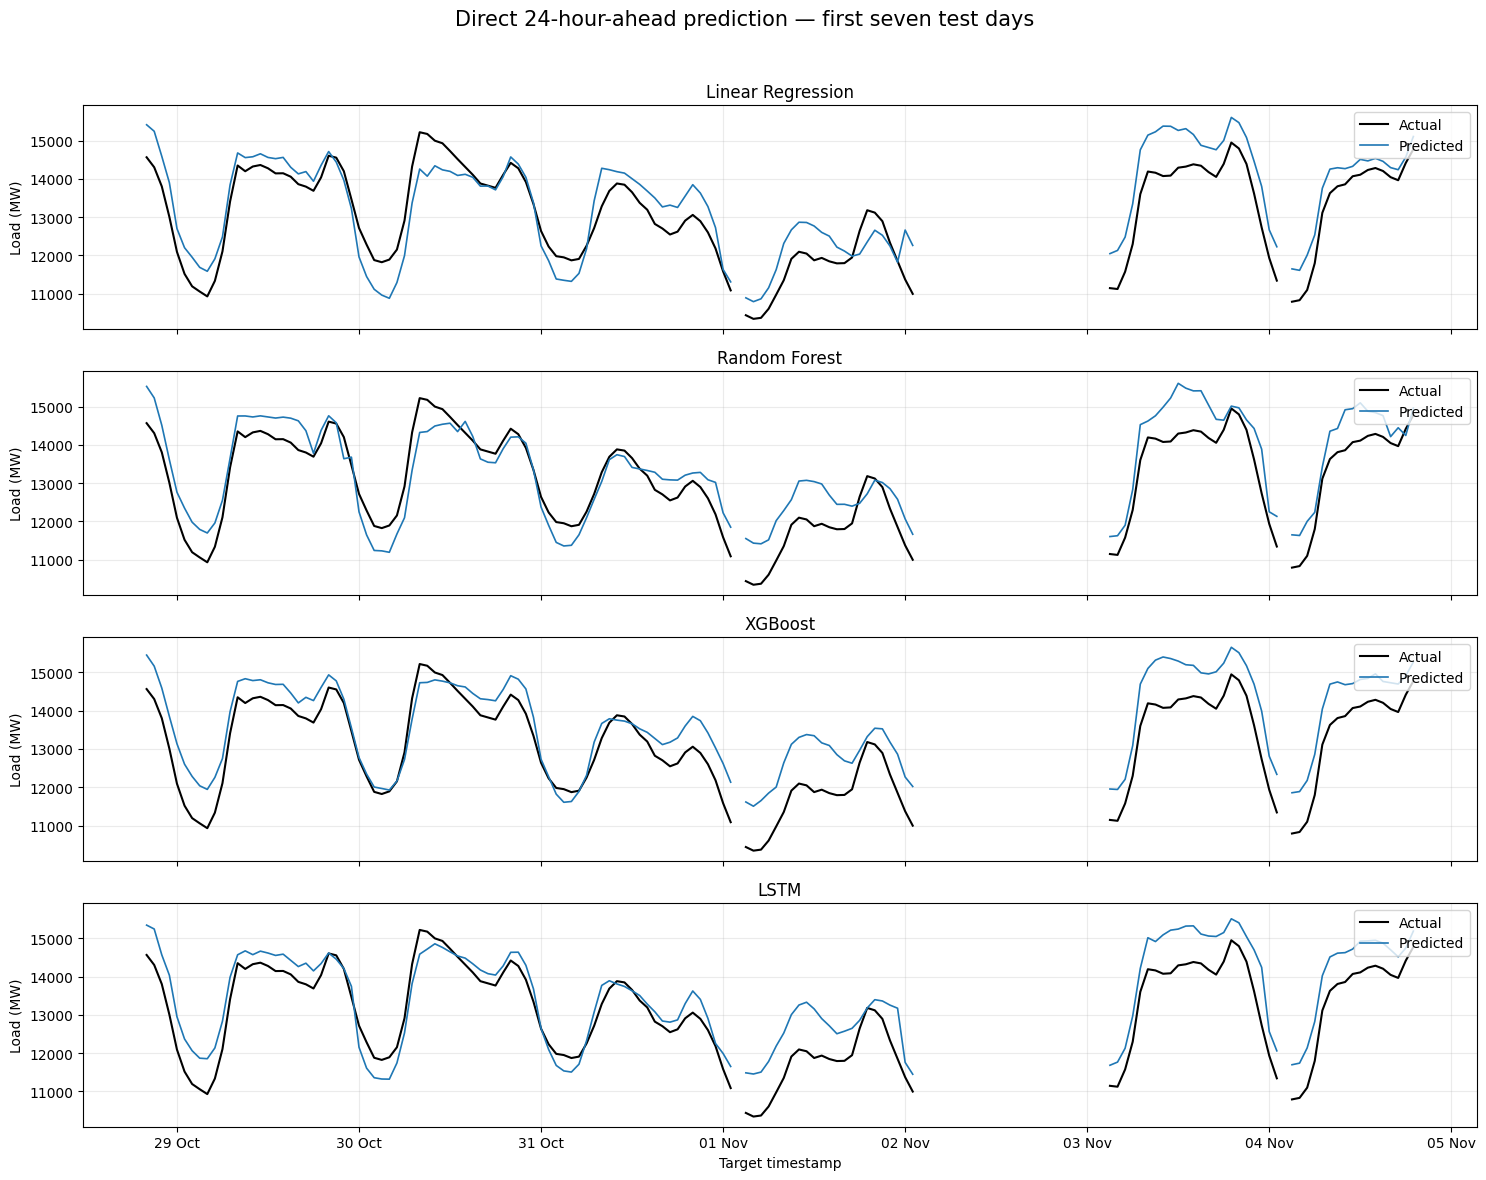

In [51]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fair_h24_plot_start = fair_h24_y_test.index.min()
fair_h24_plot_end = fair_h24_plot_start + pd.Timedelta(days=7)

fair_h24_plot_index = pd.date_range(
    start=fair_h24_plot_start,
    end=fair_h24_plot_end,
    freq="h",
    inclusive="left"
)

fair_h24_plot_actual = fair_h24_y_test.reindex(
    fair_h24_plot_index
)
fair_h24_plot_predictions = fair_h24_test_predictions.reindex(
    fair_h24_plot_index
)

plot_models = [
    "Linear Regression",
    "Random Forest",
    "XGBoost",
    "LSTM"
]

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 12),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(axes, plot_models):
    ax.plot(
        fair_h24_plot_index,
        fair_h24_plot_actual,
        color="black",
        linewidth=1.5,
        label="Actual"
    )
    ax.plot(
        fair_h24_plot_index,
        fair_h24_plot_predictions[model_name],
        color="tab:blue",
        linewidth=1.2,
        label="Predicted"
    )
    ax.set_title(model_name)
    ax.set_ylabel("Load (MW)")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)
axes[-1].set_xlabel("Target timestamp")

fig.suptitle(
    "Direct 24-hour-ahead prediction — first seven test days",
    fontsize=15
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [52]:
fair_common_test_index = fair_h1_y_test.index.intersection(
    fair_h24_y_test.index
).sort_values()

assert len(fair_common_test_index) > 0

fair_common_y = fair_h1_y_test.loc[fair_common_test_index]

np.testing.assert_allclose(
    fair_common_y.to_numpy(),
    fair_h24_y_test.loc[fair_common_test_index].to_numpy()
)

fair_horizon_models = [
    "Linear Regression",
    "Random Forest",
    "XGBoost",
    "LSTM"
]

fair_horizon_rows = []

for model_name in fair_horizon_models:
    for horizon, predictions in [
        ("1 hour", fair_h1_test_predictions),
        ("24 hours", fair_h24_test_predictions)
    ]:
        prediction = predictions.loc[
            fair_common_test_index, model_name
        ]
        assert np.isfinite(prediction.to_numpy()).all()

        metrics = evaluate_predictions(
            fair_common_y,
            prediction
        )

        fair_horizon_rows.append({
            "Model": model_name,
            "Horizon": horizon,
            **metrics
        })

fair_horizon_comparison = pd.DataFrame(
    fair_horizon_rows
).set_index(["Model", "Horizon"])

print("Shared test timestamps:", len(fair_common_test_index))
display(fair_horizon_comparison.round(3))

Shared test timestamps: 23915


RMSE (MW)  MAE (MW)  MAPE (%)     R2
Model             Horizon                                       
Linear Regression 1 hour      202.541   148.615     1.020  0.993
                  24 hours   1019.500   789.707     5.365  0.827
Random Forest     1 hour      197.415   142.919     0.985  0.993
                  24 hours    981.270   748.377     5.120  0.839
XGBoost           1 hour      152.601   113.609     0.783  0.996
                  24 hours    963.882   742.443     5.096  0.845
LSTM              1 hour      171.153   126.937     0.875  0.995
                  24 hours    953.194   727.568     4.963  0.848

In [53]:
fair_h24_seed_test_rows = []

try:
    for seed in [42, 7, 21]:
        fair_h24_lstm.set_weights(fair_h24_seed_weights[seed])

        prediction = fair_h24_target_scaler.inverse_transform(
            fair_h24_lstm.predict(
                [fair_h24_history_test, fair_h24_context_test],
                verbose=0
            )
        ).ravel()

        assert np.isfinite(prediction).all()

        fair_h24_seed_test_rows.append({
            "Seed": seed,
            **evaluate_predictions(fair_h24_y_test, prediction)
        })
finally:
    # Restore seed 42 for the existing main comparison.
    fair_h24_lstm.set_weights(fair_h24_seed_weights[42])

fair_h24_seed_test_metrics = pd.DataFrame(
    fair_h24_seed_test_rows
).set_index("Seed")

display(fair_h24_seed_test_metrics.round(3))

test_seed_rmse = fair_h24_seed_test_metrics["RMSE (MW)"]
print(f"Mean test RMSE: {test_seed_rmse.mean():.3f} MW")
print(
    "Sample standard deviation:",
    f"{test_seed_rmse.std(ddof=1):.3f} MW"
)

,RMSE (MW),MAE (MW),MAPE (%),R2
Seed,,,,
42,951.556,726.226,4.958,0.849
7,980.195,745.421,5.071,0.840
21,1011.403,782.082,5.364,0.829


Mean test RMSE: 981.051 MW
Sample standard deviation: 29.933 MW


In [54]:
for horizon, actual, predictions in [
    (1, fair_h1_y_test, fair_h1_test_predictions),
    (24, fair_h24_y_test, fair_h24_test_predictions),
]:
    export = predictions.copy()
    assert export.index.equals(actual.index)

    export.insert(0, "Actual", actual.to_numpy())
    export.index.name = "Target timestamp"

    filename = f"test_predictions_{horizon}h.csv"
    export.to_csv(filename)
    print(f"Saved {filename}: {len(export):,} test timestamps")

Saved test_predictions_1h.csv: 24,059 test timestamps
Saved test_predictions_24h.csv: 24,053 test timestamps


In [55]:
importance_rows = []

for horizon, columns, models in [
    (1, fair_h1_X_train.columns, {
        "Random Forest": fair_h1_rf,
        "XGBoost": fair_h1_xgb,
    }),
    (24, fair_h24_X_train.columns, {
        "Random Forest": fair_h24_rf,
        "XGBoost": fair_h24_xgb,
    }),
]:
    for model_name, model in models.items():
        assert len(columns) == len(model.feature_importances_)
        for feature, value in zip(columns, model.feature_importances_):
            importance_rows.append({
                "Horizon": horizon,
                "Model": model_name,
                "Feature": feature,
                "Importance": value,
            })

pd.DataFrame(importance_rows).to_csv(
    "feature_importances.csv", index=False
)
print("Saved feature_importances.csv")

Saved feature_importances.csv


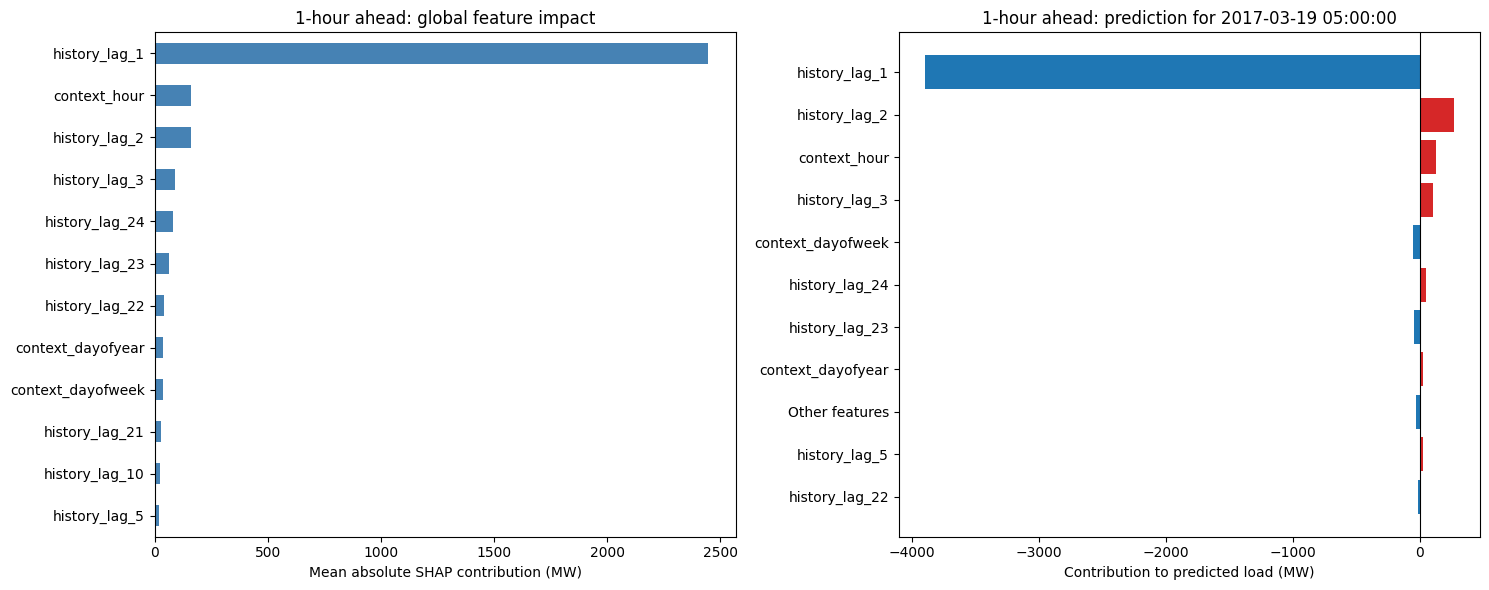

1-hour ahead | 2017-03-19 05:00:00 | baseline: 15864.1 MW | predicted: 12419.3 MW | actual: 12577.0 MW


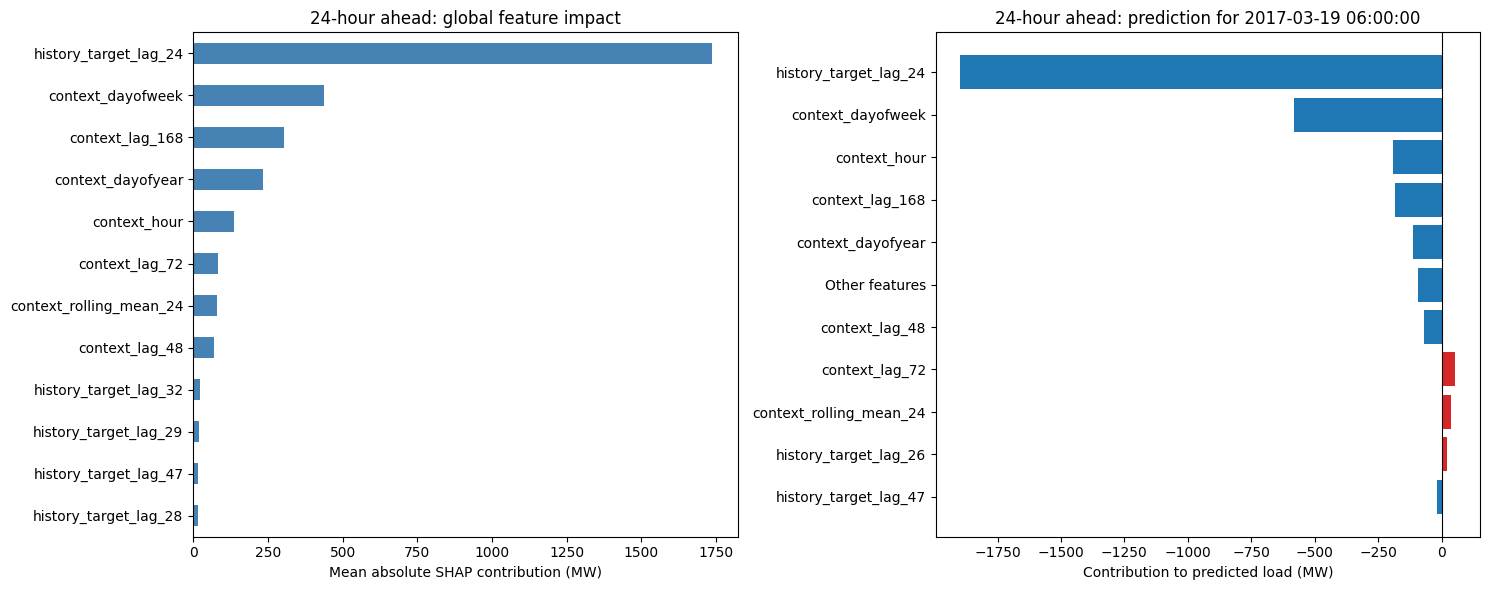

24-hour ahead | 2017-03-19 06:00:00 | baseline: 15858.2 MW | predicted: 12827.0 MW | actual: 12818.0 MW


In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

experiments = [
    ("1-hour ahead", fair_h1_xgb, fair_h1_X_test, fair_h1_y_test),
    ("24-hour ahead", fair_h24_xgb, fair_h24_X_test, fair_h24_y_test),
]

for label, model, X_test, y_test in experiments:
    # Evenly spaced test examples keep this quick to run.
    positions = np.linspace(
        0, len(X_test) - 1, min(300, len(X_test)), dtype=int
    )
    X_sample = X_test.iloc[positions]
    booster = model.get_booster()

    # Match sklearn's predict(), which uses the best iteration after early stopping.
    contributions = booster.predict(
        xgb.DMatrix(X_sample),
        pred_contribs=True,
        iteration_range=(0, model.best_iteration + 1),
    )
    predictions = model.predict(X_sample)

    # SHAP contributions plus the baseline must reproduce each prediction.
    np.testing.assert_allclose(
        contributions.sum(axis=1), predictions, rtol=1e-5, atol=0.1
    )

    global_importance = pd.Series(
        np.abs(contributions[:, :-1]).mean(axis=0),
        index=X_sample.columns,
    ).nlargest(12).sort_values()

    row = len(X_sample) // 2
    local = pd.Series(
        contributions[row, :-1], index=X_sample.columns
    )
    largest = local.abs().nlargest(10).index
    local_plot = pd.concat([
        local.loc[largest],
        pd.Series({"Other features": local.drop(largest).sum()}),
    ])
    local_plot = local_plot.reindex(local_plot.abs().sort_values().index)

    timestamp = X_sample.index[row]
    baseline = contributions[row, -1]

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    global_importance.plot.barh(ax=axes[0], color="steelblue")
    axes[0].set_title(f"{label}: global feature impact")
    axes[0].set_xlabel("Mean absolute SHAP contribution (MW)")

    axes[1].barh(
        local_plot.index,
        local_plot.values,
        color=np.where(local_plot.values >= 0, "tab:red", "tab:blue"),
    )
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set_title(f"{label}: prediction for {timestamp}")
    axes[1].set_xlabel("Contribution to predicted load (MW)")
    fig.tight_layout()
    plt.show()

    print(
        f"{label} | {timestamp} | "
        f"baseline: {baseline:.1f} MW | "
        f"predicted: {predictions[row]:.1f} MW | "
        f"actual: {y_test.loc[timestamp]:.1f} MW"
    )

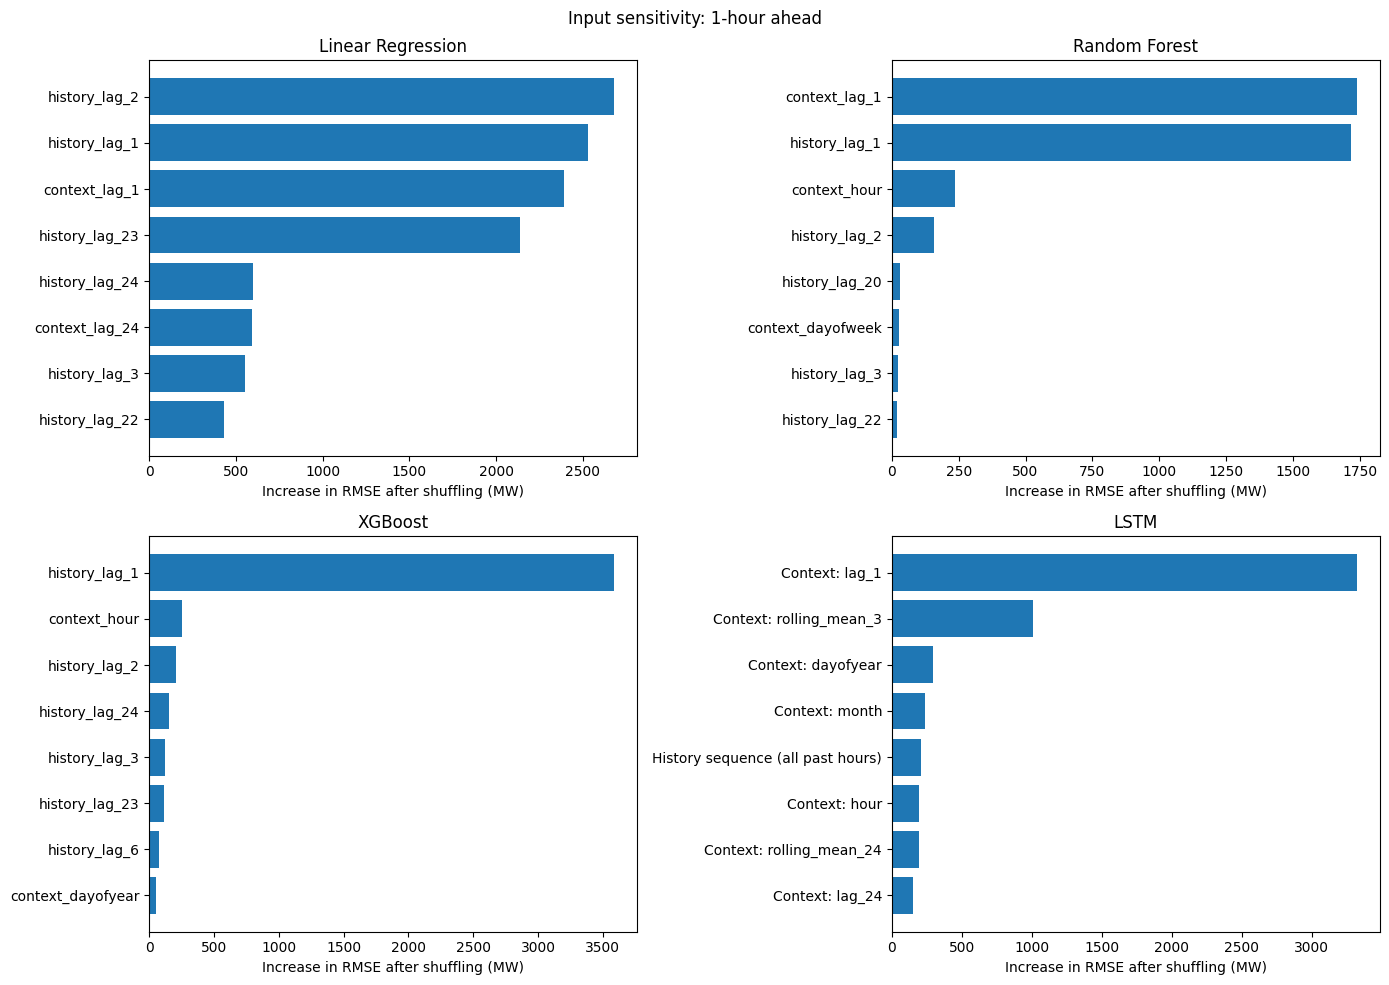

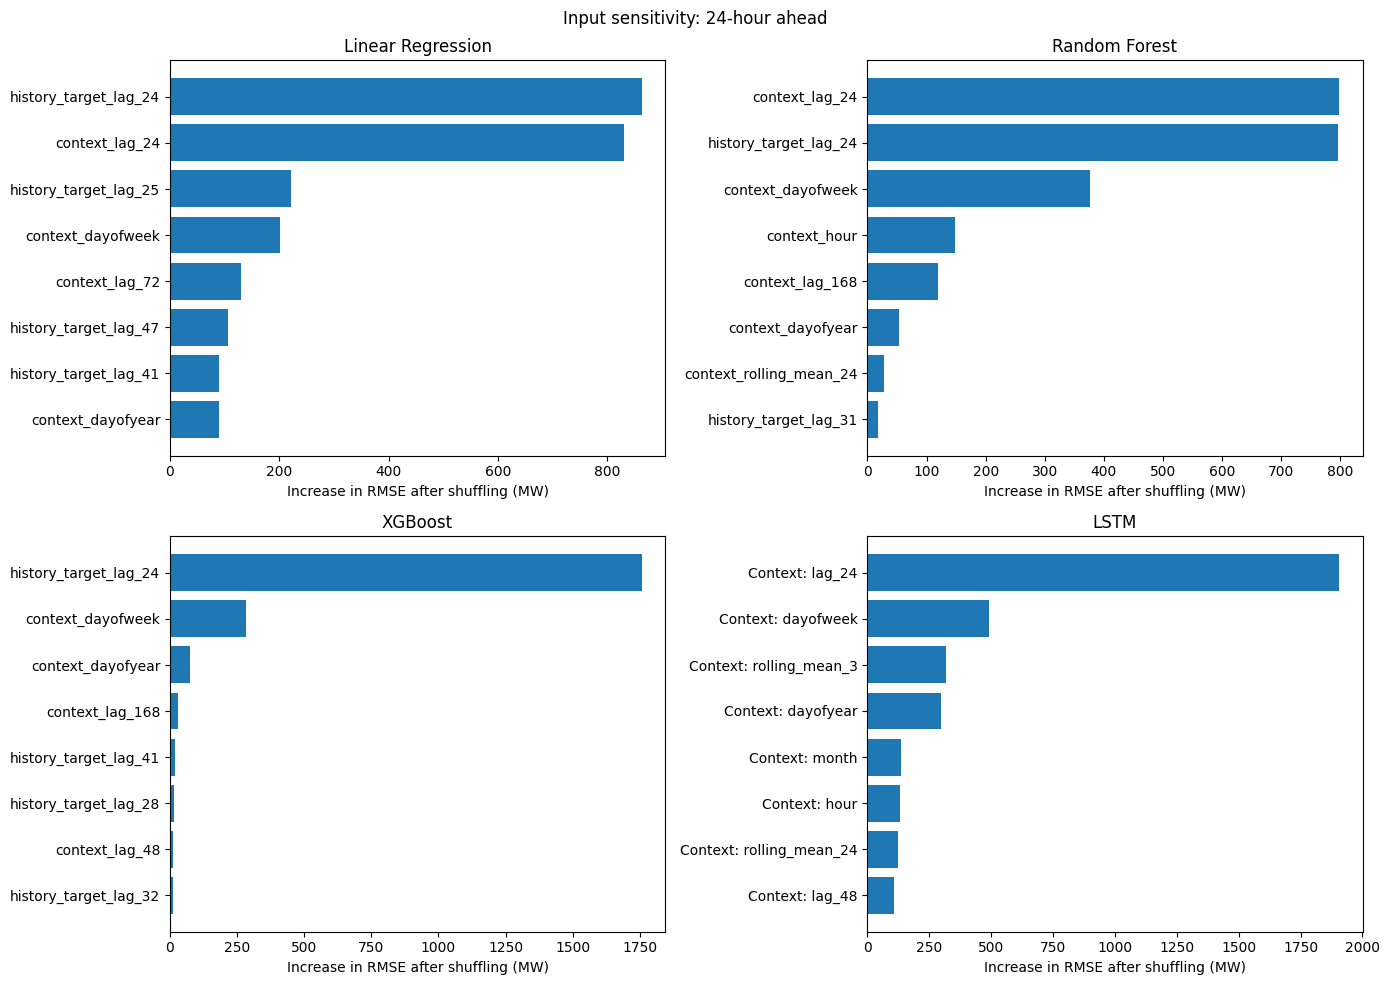

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def rmse(actual, predicted):
    return np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2))

def explain_horizon(
    label, X_test, y_test, lr, rf, xgb_model,
    lstm, history_test, context_test, context_names, target_scaler
):
    positions = np.linspace(
        0, len(X_test) - 1, min(120, len(X_test)), dtype=int
    )
    X = X_test.iloc[positions].copy()
    y = y_test.iloc[positions].to_numpy()
    rng = np.random.default_rng(42)
    rows = []

    # The three models that take tabular inputs
    for model_name, model in [
        ("Linear Regression", lr),
        ("Random Forest", rf),
        ("XGBoost", xgb_model),
    ]:
        original_rmse = rmse(y, model.predict(X))

        for feature in X.columns:
            changed = X.copy()
            changed[feature] = rng.permutation(changed[feature].to_numpy())
            changed_rmse = rmse(y, model.predict(changed))

            rows.append({
                "Horizon": label,
                "Model": model_name,
                "Input": feature,
                "RMSE increase (MW)": changed_rmse - original_rmse,
            })

    # LSTM takes a history sequence plus context features
    history = history_test[positions].copy()
    context = context_test[positions].copy()

    def lstm_predict(h, c):
        scaled_prediction = lstm.predict(
            [h, c], batch_size=256, verbose=0
        )
        return target_scaler.inverse_transform(
            scaled_prediction
        ).ravel()

    original_rmse = rmse(y, lstm_predict(history, context))

    # Shuffle whole history windows between examples
    changed_history = history[rng.permutation(len(history))]
    rows.append({
        "Horizon": label,
        "Model": "LSTM",
        "Input": "History sequence (all past hours)",
        "RMSE increase (MW)": (
            rmse(y, lstm_predict(changed_history, context))
            - original_rmse
        ),
    })

    # Shuffle context features one at a time
    for j, feature in enumerate(context_names):
        changed_context = context.copy()
        changed_context[:, j] = rng.permutation(changed_context[:, j])

        rows.append({
            "Horizon": label,
            "Model": "LSTM",
            "Input": f"Context: {feature}",
            "RMSE increase (MW)": (
                rmse(y, lstm_predict(history, changed_context))
                - original_rmse
            ),
        })

    return pd.DataFrame(rows)

xai_importance = pd.concat([
    explain_horizon(
        "1-hour ahead",
        fair_h1_X_test, fair_h1_y_test,
        fair_h1_lr, fair_h1_rf, fair_h1_xgb,
        fair_h1_lstm,
        fair_h1_history_test, fair_h1_context_test,
        fair_h1_context.columns, fair_h1_target_scaler,
    ),
    explain_horizon(
        "24-hour ahead",
        fair_h24_X_test, fair_h24_y_test,
        fair_h24_lr, fair_h24_rf, fair_h24_xgb,
        fair_h24_lstm,
        fair_h24_history_test, fair_h24_context_test,
        fair_h24_context.columns, fair_h24_target_scaler,
    ),
], ignore_index=True)

for horizon in xai_importance["Horizon"].unique():
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    for ax, model_name in zip(
        axes.flat,
        ["Linear Regression", "Random Forest", "XGBoost", "LSTM"]
    ):
        subset = xai_importance[
            (xai_importance["Horizon"] == horizon)
            & (xai_importance["Model"] == model_name)
        ]
        top = subset.nlargest(8, "RMSE increase (MW)").sort_values(
            "RMSE increase (MW)"
        )
        ax.barh(top["Input"], top["RMSE increase (MW)"])
        ax.axvline(0, color="black", linewidth=0.7)
        ax.set_title(model_name)
        ax.set_xlabel("Increase in RMSE after shuffling (MW)")

    fig.suptitle(f"Input sensitivity: {horizon}")
    fig.tight_layout()
    plt.show()

xai_importance.to_csv("xai_permutation_importance.csv", index=False)